# 2026.10.26(월) 19h~ 4강 실습 · WAV 하나로 완성하는 Log-Mel 모델 입력

**학습 목표:** 공통 WAV를 STFT 파워 → Mel 파워 → Log-Mel 특징 → 모델 입력 배열로 변환합니다.

**실습 방법:** 처음부터 순서대로 실행하고 각 실습의 **확인해야 할 결과**를 관찰하세요. 자율실습은 TODO를 먼저 작성하고, 답안은 직접 해결한 뒤 확인합니다.

**공통 WAV:** `data/tone_sequence_lesson04_16k_mono.wav` / 16kHz / 2초 / 440Hz와 880Hz. 파일이 없으면 실습에서 자동으로 만듭니다.

**최종 결과:** STFT `(257, 247)` → Mel `(40, 247)` → Log-Mel `(40, 247)` → 배치 `(1, 247, 40)`.


## 시작 준비 — 라이브러리 및 폴더 만들기

**실습 S-0 · 준비 셀:** 아래 셀을 가장 먼저 실행하세요.


In [8]:
# 목적: 분석에 필요한 라이브러리를 불러오고 실습용 data/results 폴더를 준비합니다.
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from pathlib import Path
from IPython.display import Audio, display
from scipy.io import wavfile
from scipy.signal import stft, resample_poly
from math import gcd
import json

# 한글 출력이 가능한 폰트가 있으면 그래프에 적용합니다.
fonts = {f.name for f in fm.fontManager.ttflist}
for name in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if name in fonts:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False  # 마이너스(-) 기호 깨짐 방지
plt.rcParams['figure.figsize'] = (10, 3)
plt.rcParams['figure.dpi'] = 110

DATA, RESULTS = Path('data'), Path('results')  # 입력·결과 폴더 경로
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
print('실습 폴더 준비:', DATA, RESULTS)

실습 폴더 준비: data results


---
## 1교시 · STFT에서 시간별 파워까지

**이번 교시의 목표:** 소리를 시간별 주파수 파워로 바꾸고 Mel이 필요한 이유 이해

**교시가 끝나면:** STFT 파워: (257, 247)


### 실습 1-A · 공통 WAV 생성·파형 확인

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 2초, 16kHz, 모노, 440Hz/880Hz


예제 합성음 생성: data/tone_sequence_lesson04_16k_mono.wav
공통 실습 WAV: data/tone_sequence_lesson04_16k_mono.wav / 2.00초 / 16kHz 모노
샘플 개수: 32000


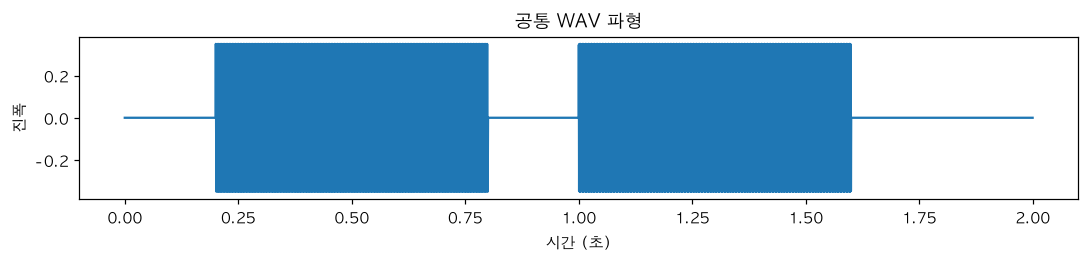

In [9]:
# 목적: 440Hz와 880Hz가 서로 다른 시간에 들어 있는 2초짜리 PCM16 합성음을 준비합니다.
# 예제 파일이 없으면 16kHz·2초 길이의 합성음을 생성
# 이후 STFT·Mel 실습에 사용할 2초 길이의 샘플 WAV 파일을 생성
# 16kHz·모노·PCM16 형식이며, 같은 경로에 파일이 없을 때만 만듭니다.
# 0.20~0.80초에는 440Hz, 1.00~1.60초에는 880Hz 소리를 넣고 나머지는 무음으로 둡니다.
# 시간과 주파수를 알고 있는 소리로 STFT·Mel 분석 결과를 확인하기 위한 예제입니다.
# 주의: 01~03 노트북이 쓰는 공통 파일 data/tone_sequence_16k_mono.wav(강사님 제공, 진폭 0.3)를 덮어쓰지 않도록,
# 4강 실습은 별도 파일 이름(tone_sequence_lesson04_16k_mono.wav)으로 만들고 읽습니다. (진폭 0.35, 0.20~0.80초/1.00~1.60초)
example_path = DATA / 'tone_sequence_lesson04_16k_mono.wav'

if True:  # 매번 동일한 수업용 WAV로 덮어써서 실습 조건을 고정합니다.
    sample_times = np.arange(32000) / 16000  # 각 샘플의 시각(초)
    generated = np.zeros(32000, dtype=np.float32)  # 우선 전체를 무음으로 준비

    # 0.20~0.80초에는 440Hz, 1.00~1.60초에는 880Hz 소리 생성
    for start, end, tone_hz in [(0.20, 0.80, 440), (1.00, 1.60, 880)]:
        mask = (sample_times >= start) & (sample_times < end)  # 해당 구간 선택
        generated[mask] = 0.35 * np.sin(
            2 * np.pi * tone_hz * sample_times[mask]
        )  # 진폭 0.35인 사인파 입력

    # 실수 파형을 PCM16 정수로 변환하여 WAV 파일로 저장
    wavfile.write(
        example_path,
        16000,
        np.round(generated * 32767).astype(np.int16)
    )
    print('예제 합성음 생성:', example_path)
print("공통 실습 WAV:", example_path, "/ 2.00초 / 16kHz 모노")

print('샘플 개수:', len(generated))
plt.figure(figsize=(10, 2.5))
plt.plot(sample_times, generated)
plt.title('공통 WAV 파형')
plt.xlabel('시간 (초)'); plt.ylabel('진폭'); plt.tight_layout(); plt.show()


**실습 1-A 마무리:** 2초, 16kHz, 모노, 440Hz/880Hz.


### Q. '파워(power)'가 뭐야? (STFT 파워, Mel 파워, 로그 파워)

수치는 이 노트북의 공통 WAV(진폭 0.35)와 같은 STFT 조건(창 512, 이동 128, `scaling='spectrum'`)으로 직접 계산했습니다. 일반 지식은 (일반 지식)으로 표시했습니다.

#### 1. 한 줄 정의
**파워 = 그 시간·주파수 성분의 "크기"를 제곱한 값** 입니다. "그 순간 그 주파수가 얼마나 **센가**"를 재는 값이고, 코드로는 이 한 줄입니다(1-B, 2-F, `logmel()`에 모두 나옴).
```python
power = np.abs(spectrum) ** 2     # spectrum: STFT 복소수 표 → 크기(abs) → 제곱
```

#### 2. 세 가지 값을 구분하기 (복소수 → 크기 → 파워)
| 단계 | 코드 | 성격 | 공통 WAV의 가장 센 칸 (직접 계산) |
|---|---|---|---|
| ① STFT 결과 | `spectrum` | **복소수**(크기 + 시작 위치) | (복소수) |
| ② 크기(magnitude) | `np.abs(spectrum)` | 0 이상의 실수. **03 노트북에서 그린 값** | **0.1743** |
| ③ **파워(power)** | `np.abs(spectrum) ** 2` | ②를 제곱. **이 4강에서 쓰는 값** | **0.0304** |
- 진폭 `A`인 사인파 하나는 이 STFT 조건에서 **크기 ≈ A ÷ 2**, **파워 ≈ A² ÷ 4**입니다(진폭 0.35 → 크기 약 0.175, 파워 약 0.0306. 실제 최댓값이 약간 작은 것은 440 Hz가 STFT 주파수 칸 위치와 딱 맞지 않기 때문으로 보입니다, 추정).
- 03에서는 크기를 그렸고, 4강에서는 파워를 그립니다. **"시간·주파수별로 얼마나 센가"를 보는 지도라는 점은 같고, 값의 눈금이 제곱만큼 다릅니다.**

#### 3. 왜 제곱하나
- 소리의 **세기(에너지)는 진폭의 제곱에 비례**합니다(일반 지식). 그래서 "세기"를 나타내려면 크기를 제곱한 파워를 씁니다.
- **진폭이 2배가 되면 파워는 4배**입니다. 직접 확인(진폭 0.1 / 0.3 / 0.6 사인파):

| 진폭 | 크기 | 파워 | 파워 (dB) |
|---|---|---|---|
| 0.1 | 0.05 | 0.0025 | -26.0 |
| 0.3 | 0.15 | 0.0225 | -16.5 |
| 0.6 | 0.30 | 0.0900 | -10.5 |
- 진폭 0.3 → 0.6(2배)에서 파워는 0.0225 → 0.0900(4배), dB로는 **약 +6 dB** 늘어납니다.

#### 4. 크기와 파워는 값의 차이가 이렇게 다릅니다
| 크기 | 파워(크기²) | 파워 dB (`10×log10`) |
|---|---|---|
| 1 | 1 | 0 dB |
| 0.5 | 0.25 | -6.0 dB |
| 0.1 | 0.01 | -20.0 dB |
- 제곱하면 **큰 값은 더 크게, 작은 값은 훨씬 더 작게** 되어 값 사이의 차이가 크게 벌어집니다. 그래서 3교시에서 **로그(dB)** 로 눌러 보기 좋게 만듭니다(3-A: 파워 1 → 0 dB, 0.1 → -10 dB, 0.01 → -20 dB, 0 → 바닥값 -100 dB).
- 같은 dB를 크기로 계산하려면 `20 × log10(크기)`입니다(`10 × log10(파워)`와 같은 결과, `np.allclose`로 확인).

#### 5. "Mel 파워"는 무엇인가
- **STFT 파워 257칸을 Mel 필터로 가중합해서 40칸으로 묶은 값**입니다(`mel_power = filters @ power`, 2-E~2-F). **크기가 아니라 파워를 합쳐서 묶는다**는 점이 핵심입니다(이렇게 파워에 필터를 적용하는 것이 흔한 관행입니다, 일반 지식).
- 그 다음 로그를 취한 것이 **Log-Mel**(`10 × log10(Mel 파워)`)입니다.

#### 6. 헷갈리기 쉬운 점 (★)
- **전기의 전력(W)이나 오디오 기기의 출력(와트)이 아닙니다.** 여기서의 파워는 신호 값을 제곱한 **상대적인 세기**입니다.
- **귀가 느끼는 소리의 크기(음량)와 같지 않습니다.** 귀는 주파수마다 다르게 느낍니다(일반 지식).
- **단위가 없는 상대값**입니다(`÷ 32768`로 만든 -1~1 눈금의 소리에서 나온 값). 퍼센트도 아닙니다.
- **파워가 크다 = 그 주파수 성분이 그 시간에 강하다**입니다. 소리가 없으면 파워는 0에 가깝습니다(이 WAV에서 프레임 중심이 0.15초 이전인 칸은 파워가 정확히 0, 직접 확인).


### 실습 1-B · 하나의 WAV로 FFT와 STFT 비교

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 두 음이 발생하는 시간과 주파수 확인


0.5초의 강한 주파수: 437.5 Hz
1.2초의 강한 주파수: 875.0 Hz
공통 WAV 길이: 32000 샘플
STFT 파워 배열: (257, 247)


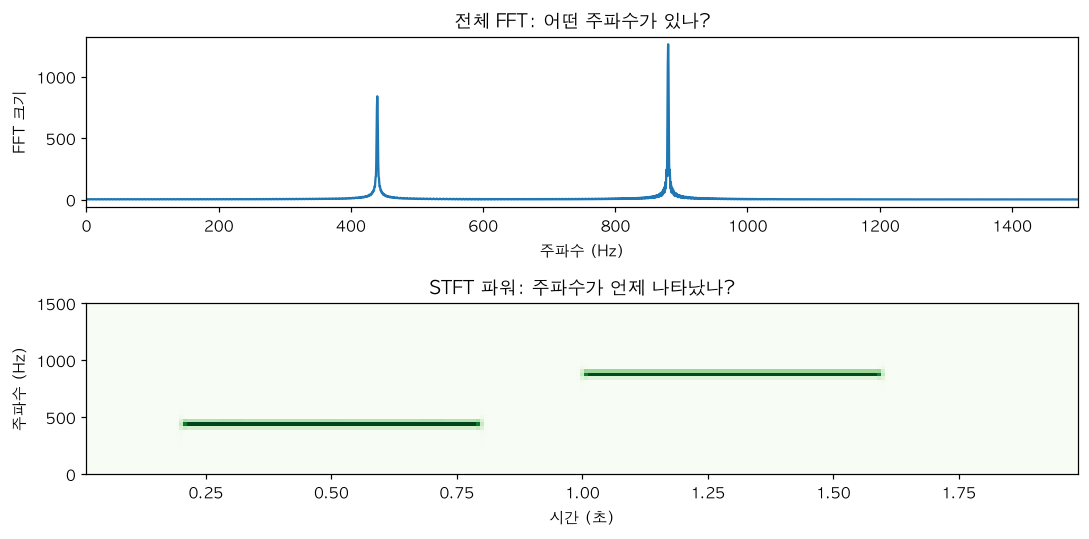

In [10]:
# 목적: 공통 2초 WAV에 들어 있는 440Hz·880Hz를 전체 FFT와 시간별 STFT에서 비교합니다.
fs_demo, pcm_demo = wavfile.read(DATA / 'tone_sequence_lesson04_16k_mono.wav')
sound_demo = pcm_demo.astype(np.float32) / 32768.0

# 전체 FFT는 어떤 주파수가 포함됐는지 보여주지만 발생 시점을 표시하지 않습니다.
fft_hz = np.fft.rfftfreq(len(sound_demo), d=1/fs_demo)
fft_amplitude = np.abs(np.fft.rfft(sound_demo * np.hanning(len(sound_demo))))

# STFT는 512샘플 창을 128샘플씩 옮기며 시간별 주파수를 분석합니다.
stft_hz_demo, stft_time_demo, stft_values_demo = stft(
    sound_demo, fs=fs_demo, window='hann', nperseg=512, noverlap=384,
    nfft=512, boundary=None, padded=False, scaling='spectrum'
)
for moment in (0.5, 1.2):
    j = int(np.argmin(np.abs(stft_time_demo - moment)))
    k = int(np.argmax(np.abs(stft_values_demo[:, j])))
    print(f'{moment:.1f}초의 강한 주파수: {stft_hz_demo[k]:.1f} Hz')
print('공통 WAV 길이:', len(sound_demo), '샘플')
stft_power_demo = np.abs(stft_values_demo) ** 2  # 시간별 STFT 파워
print('STFT 파워 배열:', stft_power_demo.shape)
assert len(sound_demo) == 32000 and stft_values_demo.shape == (257, 247)

fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].plot(fft_hz, fft_amplitude)
axes[0].set(xlim=(0, 1500), xlabel='주파수 (Hz)', ylabel='FFT 크기', title='전체 FFT: 어떤 주파수가 있나?')
axes[1].pcolormesh(stft_time_demo, stft_hz_demo, stft_power_demo, shading='auto', cmap='Greens')
axes[1].set(ylim=(0, 1500), xlabel='시간 (초)', ylabel='주파수 (Hz)', title='STFT 파워: 주파수가 언제 나타났나?')
plt.tight_layout(); plt.show()

**실습 1-B 마무리:** 두 음이 발생하는 시간과 주파수 확인.


### 실습 1-C · 낮은 음과 높은 음의 100Hz 차이 듣기

**실습 유형:** 관찰 · 실행 결과의 수치와 그림을 비교하세요.

**확인해야 할 결과:** 200→300Hz / 2,000→2,100Hz


In [11]:
# 목적: 같은 100Hz 차이를 낮은 음(200→300Hz)과 높은 음(2000→2100Hz)에서 들어 비교합니다.
sr = 16000  # 1초에 16,000개 샘플

def make_tone(hz):
    """지정한 주파수의 사인파를 0.8초 길이로 만듭니다."""
    t = np.arange(int(sr * 0.8)) / sr  # 각 샘플의 시각(초)
    sound = 0.2 * np.sin(2 * np.pi * hz * t)  # 진폭 0.2의 사인파

    # 소리 시작과 끝을 20ms 동안 서서히 줄여 경계의 클릭음을 완화합니다.
    fade = int(sr * 0.02)
    sound[:fade] *= np.linspace(0, 1, fade)
    sound[-fade:] *= np.linspace(1, 0, fade)
    return sound

pause = np.zeros(int(sr * 0.3))  # 두 음 사이 0.3초 무음
for title, first, second in [
    ('① 낮은 음: 200Hz → 300Hz', 200, 300),
    ('② 높은 음: 2,000Hz → 2,100Hz', 2000, 2100),
]:
    sound = np.concatenate([make_tone(first), pause, make_tone(second)])
    print(title)
    display(Audio(sound, rate=sr, normalize=False))  # 파형 직접 들어보기

① 낮은 음: 200Hz → 300Hz


② 높은 음: 2,000Hz → 2,100Hz


**실습 1-C 마무리:** 200→300Hz / 2,000→2,100Hz.


### Q. Mel이 뭐야? — 기초 개념 (실습 1-D에서 곡선을 보기 전에 먼저 읽기)

수치는 이 노트북의 공식(`2595 × log10(1 + Hz ÷ 700)`)과 `apply_mel_filters()`(2-E)를 같은 조건으로 계산해서 확인했습니다. 일반 지식은 (일반 지식)으로 표시했습니다.

#### 0. "Mel"은 무슨 말의 약자인가? (이름의 뜻)
- **약자가 아닙니다.** **melody(멜로디, 선율)** 에서 따온 이름으로 알려져 있습니다(일반 지식, 이 저장소의 자료에서 확인한 내용은 아님).
- 1937년에 Stevens, Volkmann, Newman이라는 연구자들이 **"소리 높낮이(음높이)를 심리적으로 재는 눈금"** 을 제안하면서 이 단위를 mel이라고 불렀다고 알려져 있습니다. 음높이가 멜로디를 이룬다는 생각에서 붙은 이름입니다.
- **사람 이름이 아니라 단위**입니다. 길이를 cm로 재듯이 음높이를 mel로 잽니다. 한국어로는 "멜"이라고 읽습니다.
- **기준점:** 1000 Hz가 약 1000 Mel이 되도록 맞춘 것이 이 단위의 기준입니다(아래 3절에서 공식 계산값 999.99로 확인).
- 앞으로 자주 보게 될 말: **Mel 스펙트로그램**(STFT를 Mel 눈금으로 묶은 그림), **Log-Mel**(거기에 로그를 취한 것, 이 노트북의 최종 특징), **MFCC**(이름에 Mel이 들어 있는 또 다른 특징. 이 수업 범위인지는 확인하지 못함).

#### 1. 한 줄 정의
**Mel(멜) = 사람 귀가 느끼는 "소리 높낮이의 간격"에 맞춰 다시 만든 주파수 눈금(자)** 입니다. Hz는 "1초에 몇 번 진동하나"를 재는 **균등한 자**이고, Mel은 같은 소리를 **귀가 느끼는 간격**으로 재는 **다른 자**입니다. 소리의 종류나 새로운 소리가 아니라 **재는 방법**입니다.

#### 2. 왜 필요한가 — 실습 1-C에서 들은 것
| 비교 | 주파수 차이 | 비율 | 귀로 들으면 | Mel 차이 (1-D 출력) |
|---|---|---|---|---|
| 200 → 300 Hz | 100 Hz | **×1.5** | 음이 **뚜렷하게 올라감** | **118.7** |
| 2,000 → 2,100 Hz | 100 Hz | ×1.05 | **거의 같은 음** | **41.0** |
- **같은 100 Hz 차이인데 귀가 느끼는 차이가 다릅니다.** 귀는 "얼마나 더했나(차이)"보다 **"몇 배나 됐나(비율)"** 로 음높이를 느낍니다. 01 노트북의 **옥타브(×2)** 와 **반음(×1.0595)** 이 비율이었던 것과 같은 생각입니다.
- 그런데 Hz 자는 어디서나 100 Hz가 똑같은 길이입니다. 그래서 **귀의 느낌에 맞게 늘이고 줄인 자**가 필요하고, 그것이 Mel입니다.

#### 3. 두 자의 모양 비교
```text
Hz 자  (같은 간격):   0 ──── 2000 ──── 4000 ──── 6000 ──── 8000 Hz

Mel 자를 같은 간격 4칸으로 나누고 Hz로 읽으면:
                      0 ─ 614 ─── 1768 ───────── 3934 ──────────────── 8000 Hz
                         └ 낮은 쪽은 촘촘 ┘         └ 높은 쪽은 성글게(넓게) ┘
```
- Mel 자의 **한 칸**은 낮은 쪽에서는 **좁은 Hz 범위**, 높은 쪽에서는 **넓은 Hz 범위**입니다. (귀는 낮은 음의 차이에 민감하고 높은 음의 차이에는 둔합니다.)
- 1-D 출력으로 읽으면: `0 → 0`, `500 → 607`, `1000 → 1000`, `2000 → 1521`, `4000 → 2146`, `8000 → 2840` Mel. **1000 Hz가 거의 1000 Mel**이 되도록 맞춘 눈금입니다(공식으로 계산하면 999.99).
- 곡선은 **낮은 쪽에서 가파르고 높은 쪽에서 완만**합니다(0 Hz 근처에서는 Hz 1당 약 1.6 Mel, 4000 Hz 근처에서는 약 0.24 Mel). 이것이 1-D 왼쪽 그림의 휘어진 모양입니다. 로그와 비슷하지만 **완전한 로그는 아닙니다**(옥타브(×2) 하나의 Mel 차이가 440→880 Hz에서 368, 880→1760 Hz에서 499, 3520→7040 Hz에서 684로 커짐).

#### 4. 음성 특징에서 Mel을 어떻게 쓰나 — 257칸을 40칸으로 묶기
- STFT 결과는 **0~8000 Hz를 31.25 Hz 간격으로 균등하게 257칸**으로 나눈 표입니다(`512 ÷ 2 + 1`).
- 이 표를 **Mel 자로 다시 40칸으로 묶는 것**이 "Mel 필터"(2-E~2-F)입니다. 칸마다 **삼각형 모양의 가중치**를 두고 주변 주파수 칸의 파워를 가중합합니다(2-A에서 `[2,4,8,2] → [4,6]`으로 연습한 것과 같은 원리).

| 구간 | STFT 칸 수 | Mel 필터 수 | 필터 하나가 묶는 범위 |
|---|---|---|---|
| 0~1000 Hz | 33칸 | **14개** | 필터 하나가 STFT 칸 2~4개를 묶음 (첫 필터 폭 약 92 Hz) |
| 1000~8000 Hz | 224칸 | **26개** | 마지막 필터는 STFT 칸 33개, 폭 약 1006 Hz |
- **낮은 주파수는 세밀하게, 높은 주파수는 뭉텅이로** 요약합니다. 귀가 중요하게 듣는 낮은 쪽 정보를 많이 남기고, 모델 입력 크기도 줄입니다(257 → 40).

#### 5. 전체 흐름 (이 노트북의 최종 결과와 연결)
```text
소리(WAV) ─STFT→ 파워 (257, 247) ─Mel 필터로 묶기→ Mel 파워 (40, 247)
                                      │
                                      └─ 로그(dB) → Log-Mel (40, 247) ─전치·배치→ 모델 입력 (1, 247, 40)
                                         (3교시)                        (4교시)
```
- **Mel은 "주파수 축을 귀 기준으로 묶는 단계"** 입니다. 시간 축(247)은 그대로입니다.
- **로그는 별개 단계**입니다. Mel로 묶은 뒤 값의 범위를 줄이려고 따로 합니다(3-A, "잡음 제거가 아님").

#### 6. 헷갈리기 쉬운 점 (★)
- **Mel 필터는 사람이 설계한 고정된 도구**이고, 모델이 학습하는 값이 아닙니다(마지막 "마무리 정리": "Mel은 사람이 설계한 필터로 주파수 칸을 묶고").
- **Mel로 바꾸면 세밀한 주파수 정보는 일부 잃습니다.** 대신 귀에 중요한 부분을 남기고 크기를 줄이는 것이 목적입니다. 20개와 40개를 비교하는 3-F가 그 세밀함의 차이를 보여 줍니다.
- 이 노트북의 Mel은 **교육용 특징**이며 Whisper 같은 특정 모델의 공식 입력과 같다고 가정하면 안 됩니다(종합 P-1 정답의 주의 문구).
- 다른 Mel 공식도 있어서(예: 라이브러리마다 약간 다름) 이 노트북은 **HTK 공식**을 씁니다(1-D 주석). 다른 도구와 숫자를 비교할 때 같은 공식인지 확인해야 합니다 (일반 지식, 이 노트북에서 비교하지 않음).

#### 7. 이 노트북에서 어디를 보면 되나
| 알고 싶은 것 | 위치 |
|---|---|
| 같은 100 Hz 차이가 왜 다르게 들리나 | 1-C (듣기), **1-E 해설** (Hz 차이 vs Mel 차이 표) |
| Hz ↔ Mel 눈금 곡선 | 1-D |
| 여러 칸을 가중합으로 묶는 원리 | 2-A ~ 2-C |
| 삼각형 Mel 필터 만들기, 그림 | 2-E ~ 2-G |
| 로그(dB) 변환 | 3-A ~ 3-D |
| 모델 입력 모양 `(1, 247, 40)` | 4-A ~ 4-C, **마지막 "마무리 정리"** |


### 실습 1-D · Hz와 Mel 눈금 그래프

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 낮은 쪽 Mel 간격이 상대적으로 큼


[Hz와 Mel 변환값]
    0 Hz →     0.0 Mel
  500 Hz →   607.4 Mel
 1000 Hz →  1000.0 Mel
 2000 Hz →  1521.4 Mel
 4000 Hz →  2146.1 Mel
 8000 Hz →  2840.0 Mel
200→300Hz: 주파수 차이 100Hz / Mel 차이 118.7
2000→2100Hz: 주파수 차이 100Hz / Mel 차이 41.0


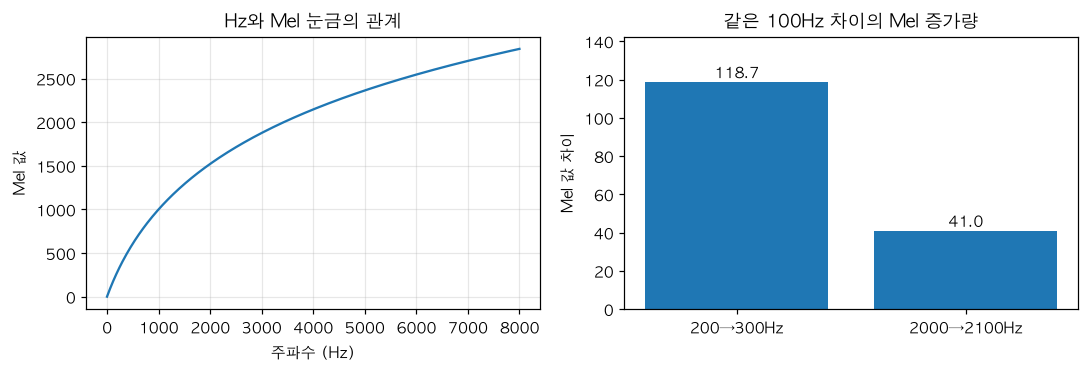

In [12]:
# 목적: Hz를 Mel 눈금으로 변환하고, 같은 100Hz 차이가 음역대에 따라 어떻게 달라지는지 확인합니다.

def hz_to_mel_intro(hz_value):
    """HTK 공식으로 Hz 값을 Mel 눈금으로 변환합니다(수학식의 유도는 학습 범위 밖)."""
    return 2595.0 * np.log10(1.0 + np.asarray(hz_value) / 700.0)

# 1. 대표적인 주파수를 Mel 눈금으로 변환해 비교합니다.
frequency_samples = [0, 500, 1000, 2000, 4000, 8000]
print('[Hz와 Mel 변환값]')
for hz_value in frequency_samples:
    print(f'{hz_value:5d} Hz → {hz_to_mel_intro(hz_value):7.1f} Mel')

# 2. Hz에 따른 Mel 값의 변화를 곡선으로 표시합니다.
hz_range = np.linspace(0, 8000, 401)  # 0~8,000Hz 사이 관찰용 주파수
mel_curve = hz_to_mel_intro(hz_range)

# 3. 같은 100Hz 차이를 낮은 구간과 높은 구간에서 비교합니다.
frequency_pairs = [(200, 300), (2000, 2100)]
mel_gaps = []
for first, second in frequency_pairs:
    gap = float(hz_to_mel_intro(second) - hz_to_mel_intro(first))
    mel_gaps.append(gap)
    print(f'{first}→{second}Hz: 주파수 차이 {second-first}Hz / Mel 차이 {gap:.1f}')

# 4. 왼쪽은 전체 Hz–Mel 관계, 오른쪽은 두 구간의 Mel 증가량입니다.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(hz_range, mel_curve)
axes[0].set(title='Hz와 Mel 눈금의 관계', xlabel='주파수 (Hz)', ylabel='Mel 값')
axes[0].grid(alpha=0.3)

axes[1].bar(['200→300Hz', '2000→2100Hz'], mel_gaps)
axes[1].set(title='같은 100Hz 차이의 Mel 증가량', ylabel='Mel 값 차이')
for i, gap in enumerate(mel_gaps):
    axes[1].text(i, gap + 2, f'{gap:.1f}', ha='center')  # 막대 위 숫자 표기
axes[1].set_ylim(0, max(mel_gaps) * 1.2)
plt.tight_layout()
plt.show()


**실습 1-D 마무리:** 낮은 쪽 Mel 간격이 상대적으로 큼.


### 실습 1-E · Hz 차이와 Mel 차이 계산

**실습 유형:** 자율실습 · TODO를 먼저 해결한 뒤 결과를 확인하세요.

**확인해야 할 결과:** 100Hz 차이가 Mel에서는 다르게 나타남


In [6]:
# 목적: 1교시 자율실습 — 주파수의 절대·상대 차이와 Mel 눈금 차이를 비교합니다.
# TODO 1: 아래 주파수 쌍을 반복문으로 처리하세요.
# TODO 2: 주파수 차이(Hz), 상대 변화율(%), Mel 값 차이를 출력하세요.
# TODO 3: 두 결과가 왜 다른지 출력 아래에 한 문장으로 적어 보세요.

frequency_pairs = [(200, 300), (2000, 2100)]
# 이 아래에 직접 코드를 작성하세요.


<details><summary><strong>실습 1-E · 정답 및 해설 펼치기 (먼저 스스로 작성하세요)</strong></summary>

#### 실습 1-E 정답 코드 — 직접 풀고 확인하세요

| 구간 | Hz 차이 | 상대 변화율 | Mel 차이 (약) |
|---|---:|---:|---:|
| 200→300Hz | 100Hz | 50.0% | 118.7 |
| 2,000→2,100Hz | 100Hz | 5.0% | 41.0 |

**해설:** 두 구간의 Hz 차이는 동일하지만 시작 주파수가 다릅니다. Mel 척도는 높은 주파수로 갈수록 같은 Hz 차이가 **더 작은 Mel 차이**가 되도록 설계되었습니다. 상대 변화율이 Mel 계산 공식 자체는 아니라는 점도 기억합니다.

</details>


In [7]:
# 목적: 1교시 정답 — 같은 100Hz 차이를 상대 변화율과 Mel 눈금으로 함께 비교합니다.
frequency_pairs = [(200, 300), (2000, 2100)]
for first, second in frequency_pairs:
    gap_hz = second - first                        # 물리적인 주파수 차이
    relative = gap_hz / first * 100                # 시작 주파수 대비 변화율
    gap_mel = hz_to_mel_intro(second) - hz_to_mel_intro(first)  # Mel 눈금 차이
    print(f'{first}→{second}Hz: 차이 {gap_hz}Hz / 상대 변화율 {relative:.1f}% / Mel 차이 {gap_mel:.1f}')


200→300Hz: 차이 100Hz / 상대 변화율 50.0% / Mel 차이 118.7
2000→2100Hz: 차이 100Hz / 상대 변화율 5.0% / Mel 차이 41.0


**실습 1-E 마무리:** 100Hz 차이가 Mel에서는 다르게 나타남.


---
# 2026.10.26(월) 20h~

## 2교시 · Mel 필터로 주파수 파워 묶기

**이번 교시의 목표:** 가중합 원리부터 실제 Mel 파워 생성까지

**교시가 끝나면:** Mel 파워: (40, 247)


### 실습 2-A · 네 주파수 파워를 두 특징으로 가중합

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** [2,4,8,2] → [4,6]


In [13]:
# 목적: 주파수 파워 4개에 가중치를 적용하여 Mel 필터와 비슷한 특징 2개를 계산합니다.
power_bins = np.array([2.0, 4.0, 8.0, 2.0]) # 한 시간 프레임의 네 주파수 칸의 파워
weights = np.array([[1.0, 0.5, 0.0, 0.0],
                    [0.0, 0.0, 0.5, 1.0]])
# @는 행렬 곱셈 연산자. 각 행의 가중치와 주파수 파워를 위치별로 곱한 후 모두 더함
grouped = weights @ power_bins             # 각 행의 가중치를 곱한 뒤 더함
print('원래 네 칸:', power_bins)
print('묶은 두 칸:', grouped)

원래 네 칸: [2. 4. 8. 2.]
묶은 두 칸: [4. 6.]


**실습 2-A 마무리:** [2,4,8,2] → [4,6].


### Q. 실습 2-A: '묶은 두 칸'이 [4, 6]이 되는 계산 과정과 이유

수치는 이 셀의 `power_bins`, `weights`로 직접 계산해서 확인했습니다. 이 실습은 **257칸을 40칸으로 묶는 Mel 필터의 원리를 숫자 4개로 줄여 보는 것**입니다.

#### 1. 무엇을 하는 연산인가: 가중합 (가중치를 곱해서 모두 더하기)
```python
power_bins = np.array([2.0, 4.0, 8.0, 2.0])      # 입력: 주파수 칸 4개의 파워
weights = np.array([[1.0, 0.5, 0.0, 0.0],        # 첫 번째 필터
                    [0.0, 0.0, 0.5, 1.0]])       # 두 번째 필터
grouped = weights @ power_bins                    # 가중합
```
- **입력 4개 → 출력 2개**로 줄입니다. 출력 하나하나가 "여러 칸을 묶은 값"입니다.
- 평균이 아닙니다. **"비중을 곱해서 더한 값"** 입니다(비중의 합이 1이 아니라서 평균이라고 하면 틀립니다. 첫 번째 필터의 가중치 합은 `1.0 + 0.5 = 1.5`).

#### 2. `weights`의 모양을 읽는 법
```text
              칸0   칸1   칸2   칸3        ← 열: 입력 주파수 칸 번호
첫 번째 필터 [ 1.0   0.5   0.0   0.0 ]     ← 행 0: "앞쪽 두 칸(0, 1)을 묶는다"
두 번째 필터 [ 0.0   0.0   0.5   1.0 ]     ← 행 1: "뒤쪽 두 칸(2, 3)을 묶는다"
```
- **행 = 필터(출력 하나), 열 = 입력 칸**입니다. 가중치가 0이면 그 칸은 그 필터에서 **무시**되고, 클수록 **많이 반영**됩니다.
- 첫 번째 필터는 칸 0에 가장 큰 가중치(1.0), 칸 1에 절반(0.5)을 줍니다. 두 번째 필터는 칸 3에 1.0, 칸 2에 0.5를 줍니다. **한 필터가 자기 담당 칸에서 가장 크고 옆으로 갈수록 작아지는 모양**이 삼각형 Mel 필터와 비슷합니다(실제 필터는 가운데가 1이고 양쪽으로 0까지 줄어듦).

#### 3. `@`(행렬 곱셈)가 하는 일
- `@`는 **각 행을 입력과 곱해서 모두 더하는** 연산입니다. 행이 2개라서 출력이 2개입니다.
- 모양: `weights (2, 4) @ power_bins (4,) → (2,)`.

#### 4. 계산 과정 (한 칸씩)
**첫 번째 출력** (행 0):
| | 칸 0 | 칸 1 | 칸 2 | 칸 3 | 합 |
|---|---|---|---|---|---|
| 파워 | 2 | 4 | 8 | 2 | |
| 가중치 | 1.0 | 0.5 | 0.0 | 0.0 | |
| 곱 | 2 | 2 | 0 | 0 | **4** |

**두 번째 출력** (행 1):
| | 칸 0 | 칸 1 | 칸 2 | 칸 3 | 합 |
|---|---|---|---|---|---|
| 파워 | 2 | 4 | 8 | 2 | |
| 가중치 | 0.0 | 0.0 | 0.5 | 1.0 | |
| 곱 | 0 | 0 | 4 | 2 | **6** |

- 식으로 쓰면: `2×1.0 + 4×0.5 + 8×0 + 2×0 = 4`, `2×0 + 4×0 + 8×0.5 + 2×1.0 = 6`. 그래서 `[2, 4, 8, 2] → [4, 6]`입니다.

#### 5. 왜 이런 결과가 나오나
- **첫 번째 결과 4**는 앞쪽 칸(2, 4)에서 나온 값이고, **두 번째 결과 6**은 뒤쪽 칸(8, 2)에서 나온 값입니다. 가장 센 칸(8)이 뒤쪽에 있지만 가중치가 0.5라서 절반만 반영되어 `4`가 되었고, 그 옆의 2(가중치 1.0)가 더해져 `6`이 됐습니다.
- **칸 0과 칸 3은 한 필터에서만, 칸 1과 칸 2도 한 필터에서만** 쓰입니다(이 예제는 필터가 서로 겹치지 않게 단순화함). 실제 Mel 필터는 이웃 필터와 **일부 겹칩니다**.
- 이 방식이 **음성 특징**에서 하는 일: 여러 주파수 칸의 파워를 **한 개의 특징으로 요약**합니다. 칸을 얼마나 묶을지(범위)와 얼마나 반영할지(가중치)는 필터 모양이 정합니다.

#### 6. 실제 음성 특징과 같은 원리
```text
이 실습         :  weights (2, 4)    @  power_bins (4,)      →  (2,)
실제 Mel 필터   :  filters (40, 257) @  power (257, 247)     →  mel_power (40, 247)
```
- 실제로는 **257개 주파수 칸의 파워를 40개 Mel 필터로 묶어서 40개 Mel 파워**로 만듭니다(2-E~2-F). 시간 축(247)은 그대로 두고 주파수 축만 줄입니다. 이 실습은 그 원리를 숫자 4개로 직접 계산해 본 것입니다.
- 이어지는 2-B는 이 4개 → 2개의 변화를 막대그래프로 보여 주고, 2-C는 가중치 한 칸만 바꿔서 결과가 어떻게 변하는지 확인합니다.


### 실습 2-B · 가중합 전후 막대그래프

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 입력 4개와 출력 2개 비교


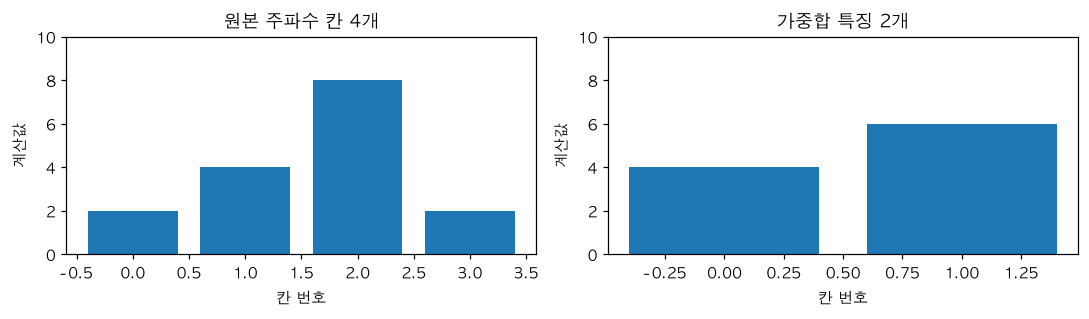

In [14]:
# 목적: 가중합 전의 주파수 칸 4개와 결과 특징 2개를 막대그래프로 비교합니다.
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].bar(range(4), power_bins)   # 원본 파워 4개
axes[0].set_title('원본 주파수 칸 4개')
axes[1].bar(range(2), grouped)      # 가중합 결과 2개
axes[1].set_title('가중합 특징 2개')
for ax in axes:
    ax.set(xlabel='칸 번호', ylabel='계산값', ylim=(0, 10))
plt.tight_layout()
plt.show()

# 왼쪽 그래프는 STFT 분석 후의 주파수별 파워를, 오른쪽 그래프는 Mel 필터로 가중합한 특징을 단순화하여 보여줍니다.
# 실제로는 257개 주파수 성분을 40개 Mel 특징으로 묶는 과정과 같은 원리입니다.

**실습 2-B 마무리:** 입력 4개와 출력 2개 비교.


### 실습 2-C · 첫 번째 필터 가중치 변경

**실습 유형:** 자율실습 · TODO를 먼저 해결한 뒤 결과를 확인하세요.

**확인해야 할 결과:** [4,6] → [3,6]


In [10]:
# 목적: 2교시 자율실습 — 원본 가중치를 보존한 채 첫 번째 필터만 수정해 결과를 비교합니다.
# TODO: weights.copy()로 복사하고 [0, 1]의 값을 0.25로 수정하세요.
# TODO: 원래 결과 grouped와 새 가중합을 출력하세요.
# 이 아래에 코드를 작성하세요.

<details><summary><strong>실습 2-C · 정답 및 해설 펼치기 (먼저 스스로 작성하세요)</strong></summary>

#### 실습 2-C 정답 및 해설

첫 번째 가중합은 `2×1 + 4×0.25 = 3`, 두 번째는 `8×0.5 + 2×1 = 6`입니다. **원본 주파수 파워가 바뀐 것이 아니라 첫 번째 필터의 가중치만 바뀌었습니다.**

</details>


In [16]:
# 목적: 첫 번째 필터의 가중치만 바뀌었을 때 출력이 [4, 6]에서 [3, 6]으로 변하는지 확인합니다.
changed = weights.copy()          # 원본 weights 유지
changed[0, 1] = 0.25             # 첫 번째 출력에만 영향을 주는 가중치 변경
changed_result = changed @ power_bins  # 변경된 필터로 가중합
print('변경 전:', grouped, '/ 변경 후:', changed_result)
print('원본 가중치 유지:', weights[0, 1] == 0.5)

변경 전: [4. 6.] / 변경 후: [3. 6.]
원본 가중치 유지: True


**실습 2-C 마무리:** [4,6] → [3,6].


### Q. 실습 2-C: '변경 후 가중치'로 [4, 6]이 [3, 6]이 되는 계산 과정과 이유

수치는 이 셀의 `power_bins`, `weights`로 직접 계산해서 확인했습니다.

#### 1. 무엇을 바꿨나 — 한 칸만
```python
changed = weights.copy()      # 원본 weights를 복사
changed[0, 1] = 0.25          # 0번 행(첫 번째 필터), 1번 열(두 번째 주파수 칸)의 가중치를 0.5 → 0.25로
```
- `changed[행, 열]`입니다. **행 = 몇 번째 필터(출력), 열 = 몇 번째 주파수 칸**입니다. 그래서 `changed[0, 1]`은 **"첫 번째 필터가 두 번째 주파수 칸(파워 4)을 얼마나 반영하나"** 를 0.5에서 0.25로 바꾼 것입니다.
- `power_bins`(입력 파워 `[2, 4, 8, 2]`)는 **바뀌지 않았습니다.** 바뀐 것은 "어떻게 묶을지"를 정하는 가중치뿐입니다.

| | 첫 번째 필터 (행 0) | 두 번째 필터 (행 1) |
|---|---|---|
| 원래 `weights` | `[1.0, 0.5, 0.0, 0.0]` | `[0.0, 0.0, 0.5, 1.0]` |
| 변경 `changed` | `[1.0, 0.25, 0.0, 0.0]` (둘째 값만 변경) | `[0.0, 0.0, 0.5, 1.0]` (그대로) |

#### 2. 계산 과정 (가중합 = 칸마다 "가중치 × 파워"를 곱해서 모두 더함)
**첫 번째 출력** (행 0):
| | 칸 0 | 칸 1 | 칸 2 | 칸 3 | 합 |
|---|---|---|---|---|---|
| 파워 | 2 | 4 | 8 | 2 | |
| 가중치(원래) | 1.0 | 0.5 | 0 | 0 | |
| 곱 | 2 | 2 | 0 | 0 | **4** |
| 가중치(변경) | 1.0 | **0.25** | 0 | 0 | |
| 곱 | 2 | **1** | 0 | 0 | **3** |

- 변경 후 식: `2×1.0 + 4×0.25 + 8×0 + 2×0 = 2 + 1 = 3`
- 칸 1의 가중치가 0.5 → 0.25로 **절반**이 되어 그 칸의 기여가 `4×0.5 = 2`에서 `4×0.25 = 1`로 **1만큼 줄었고**, 그만큼 결과가 `4 → 3`이 됐습니다.

**두 번째 출력** (행 1): 가중치를 바꾸지 않았으므로 `0×2 + 0×4 + 8×0.5 + 2×1.0 = 4 + 2 = 6` 그대로입니다. **한 필터의 가중치는 그 필터의 출력에만 영향을 줍니다.**

#### 3. 왜 이런 결과가 나오나 (핵심 3가지)
1. **가중치는 "이 칸을 얼마나 반영할까"의 비율입니다.** 가중치가 클수록 그 칸의 파워가 결과에 많이 들어가고, 0이면 전혀 안 들어갑니다. 그래서 가중치를 줄이면 결과도 그만큼 줄어듭니다.
2. **결과 = 각 칸의 기여를 더한 것**이라서, 한 칸의 기여가 `Δ`만큼 변하면 결과도 정확히 `Δ`만큼 변합니다(`-1`).
3. **필터마다 따로 계산**됩니다. `changed @ power_bins`에서 행 0과 행 1은 서로 독립이라 행 1은 그대로입니다.

#### 4. `.copy()`를 왜 쓰나 (셀의 두 번째 출력 `원본 가중치 유지: True`의 뜻)
- `changed = weights.copy()`는 **복사본**을 만듭니다. 복사본을 고쳐도 원본 `weights`는 그대로라서 `weights[0, 1] == 0.5`가 `True`입니다.
- 만약 `changed = weights`(복사 없이 이름만 하나 더 붙임)였다면 **같은 배열을 두 이름으로 가리키는 것**이라서, `changed[0, 1] = 0.25`가 **원본도 함께 바꿉니다**(직접 확인: 원본 `weights[0, 1]`도 `0.25`가 됨). 그러면 "변경 전 `[4, 6]`과 변경 후를 비교"할 수 없게 됩니다.

#### 5. 실제 Mel 필터와 연결
- 실제 Mel 필터(2-E)도 같은 구조입니다. **필터 하나의 가중치 한 칸을 바꾸면 그 필터의 Mel 특징 하나만 변합니다.** 다만 행이 40개, 열이 257개라서 `(40, 257)` 가중치 표가 됩니다.
- 이 실습이 말하려는 것: **Mel 특징의 값은 "입력 파워"와 "필터 모양(가중치)" 두 가지로 결정**됩니다. 입력이 같아도 필터가 다르면 다른 특징이 나옵니다.


### 실습 2-D · 공통 WAV 읽기 함수 준비

**실습 유형:** 함수 정의 · 이 셀에서 함수를 정의한 뒤 이후 실습에서 사용합니다.

**확인해야 할 결과:** PCM16 WAV → float32 파형


In [15]:
# 목적: PCM16 WAV를 실수 파형으로 읽고, 계산 설정·관찰 기록을 UTF-8 JSON으로 저장합니다.
def load_audio(path):
    """PCM16 WAV 파일 → (샘플링레이트, -1~1 부근의 float32 파형)."""
    path = Path(path)
    if not path.is_file():  # 파일이 실제로 존재하는지 검사
        raise FileNotFoundError(f'음성 파일이 없습니다: {path}')
    rate, samples = wavfile.read(path)  # WAV의 SR과 PCM 샘플 읽기
    if samples.dtype != np.int16 or samples.ndim not in (1, 2) or samples.size == 0:
        raise ValueError('샘플이 있는 PCM16 WAV(모노/스테레오) 파일만 사용합니다.')
    return int(rate), samples.astype(np.float32) / 32768.0  # 정수→실수 정규화


def save_json(path, obj):
    """설정과 관찰 결과를 한글이 유지되는 JSON 파일로 저장합니다."""
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')

**실습 2-D 마무리:** PCM16 WAV → float32 파형.


# 2026.10.26(월) 21h~

### 실습 2-E · 삼각형 Mel 필터 함수 준비

**실습 유형:** 함수 정의 · 이 셀에서 함수를 정의한 뒤 이후 실습에서 사용합니다.

**확인해야 할 결과:** 가중치 배열: (40,257)


In [17]:
# 목적: 삼각형 Mel 필터를 만들어 STFT 파워에 적용하고 Mel 파워를 반환합니다.
def apply_mel_filters(hz, power, sr, n_mels=40):
    """STFT 주파수별 파워 → (Mel 파워, Mel 필터 가중치)."""

    # Hz와 Mel 눈금을 서로 변환하는 HTK 공식(수학적 유도는 학습 범위 밖)
    hz_to_mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0) # lambda 표현식 = 간이 함수
    mel_to_hz = lambda mel: 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    # 필터 3개를 만들려면 기준점이 5개 필요(필터 개수 + 2 = 기준점 개수)
    # 40개 필터를 만들면 기준점은 42개가 필요
    # 1. Mel 눈금에서 n_mels+2개의 기준점을 일정한 간격으로 배치
    mel_edges = np.linspace(hz_to_mel(0), hz_to_mel(sr / 2), n_mels + 2)

    # 2. 각 기준점이 실제 몇 Hz인지 계산(원래 음성의 주파수가 바뀌지는 않음)
    edges = mel_to_hz(mel_edges)

    # 3. (Mel 필터 개수, STFT 주파수 칸 수) 형태의 가중치 표 준비 = 실질적인 삼각형 필터 만듦
    filters = np.zeros((n_mels, len(hz)), dtype=np.float64)

    # 4. 왼쪽 0 → 중심 1 → 오른쪽 0인 삼각형 필터를 하나씩 생성
    for k in range(n_mels):
        left, center, right = edges[k:k+3]  # k번째 필터의 기준점 3개
        filters[k] = np.maximum(
            0,
            np.minimum(
                (hz - left) / (center - left),    # 왼쪽에서 중심으로 증가
                (right - hz) / (right - center)   # 중심에서 오른쪽으로 감소
            )
        )

    # 5. 주파수별 파워를 각 필터의 가중치로 묶어 Mel 파워 계산
    mel_power = filters @ power
    return mel_power, filters  # 특징 값과 필터 모양 확인용 배열


**실습 2-E 마무리:** 가중치 배열: (40,257).


### 실습 2-F · STFT 파워를 실제 Mel 파워로 변환

Mel 파워는 음성의 특징을 숫자 행렬로 바꿔서 나타냄/표현(o) Mel 파워로 음성을 표현(x)

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** (257,247) → (40,247)


In [18]:
# 목적: 같은 WAV의 STFT 파워를 40개 Mel 필터로 가중합합니다. (아직 로그 변환하지 않음)
sr, audio = load_audio(DATA / 'tone_sequence_lesson04_16k_mono.wav')
hz, times, spectrum = stft(
    audio, fs=sr, window='hann', nperseg=512, noverlap=384,
    nfft=512, boundary=None, padded=False, detrend=False, scaling='spectrum'
)
power = np.abs(spectrum) ** 2                   # (주파수 257, 시간 247)
mel_power, mel_filters = apply_mel_filters(hz, power, sr, n_mels=40)
print('입력 파형:', audio.shape, f'({len(audio)/sr:.2f}초)')
print('STFT 파워:', power.shape)
print('Mel 필터 가중치:', mel_filters.shape)
print('Mel 파워:', mel_power.shape)
assert power.shape == (257, 247)
assert mel_filters.shape == (40, 257)
assert mel_power.shape == (40, 247)
print('✓ 257개 주파수 파워가 40개 Mel 파워로 요약됐습니다. 로그 변환은 3교시에서 합니다.')

입력 파형: (32000,) (2.00초)
STFT 파워: (257, 247)
Mel 필터 가중치: (40, 257)
Mel 파워: (40, 247)
✓ 257개 주파수 파워가 40개 Mel 파워로 요약됐습니다. 로그 변환은 3교시에서 합니다.


**실습 2-F 마무리:** (257,247) → (40,247).


### 실습 2-G · 삼각형 필터와 Mel 파워 관찰

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 필터 가중치 그림 + 시간별 Mel 파워 그림


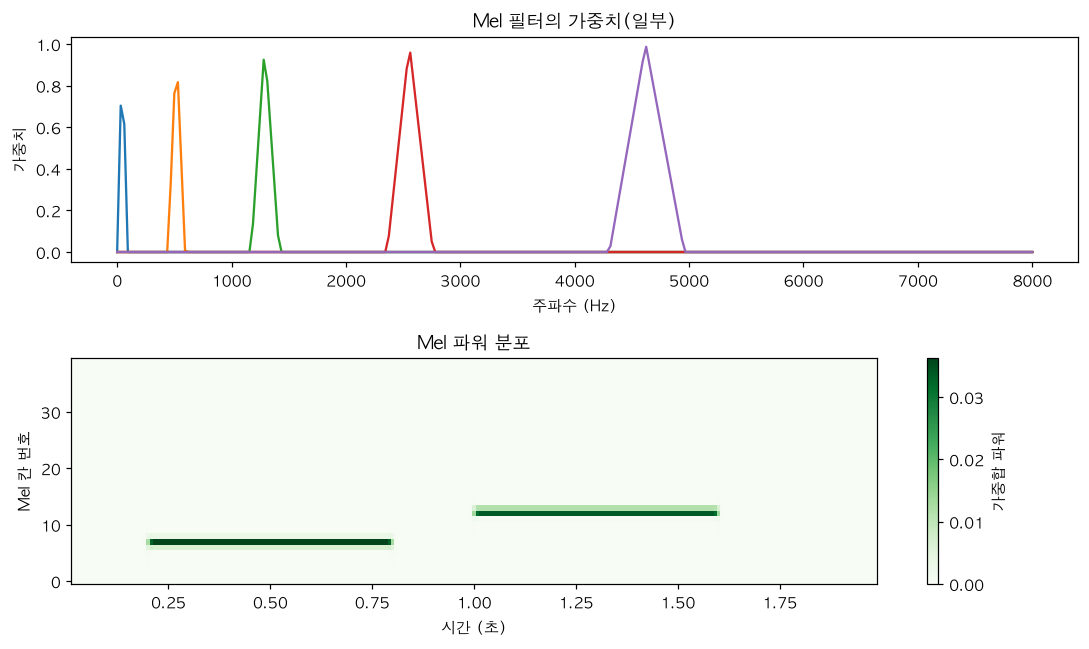

In [23]:
# 목적: Mel 필터의 삼각형 가중치와 시간에 따른 Mel 파워 분포를 시각화합니다.

# 위아래 2개의 그래프 생성
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# 1. Mel 필터의 삼각형 가중치 확인
# 전체 40개 필터 중 8개 간격으로 5개 필터를 선택하여 표시
# .T는 배열의 행과 열을 바꾸어 주파수별 가중치를 그래프로 표현
axes[0].plot(hz, mel_filters[::8].T)
# axes[0].plot(hz, mel_filters[::].T) # 전체 그려서 확인해볼 수 있음
axes[0].set(title='Mel 필터의 가중치(일부)',
            xlabel='주파수 (Hz)', ylabel='가중치')

# 2. 시간에 따른 Mel 파워 분포 확인
# 가로축: 시간, 세로축: Mel 필터 번호(0~39)
# 색상: 각 시간과 Mel 필터에서 계산된 파워의 크기
image = axes[1].pcolormesh(
    times,
    np.arange(40),
    mel_power,
    shading='auto',
    cmap='Greens'
)
axes[1].set(title='Mel 파워 분포',
            xlabel='시간 (초)', ylabel='Mel 칸 번호')

# 색상의 의미를 나타내는 막대 추가
fig.colorbar(image, ax=axes[1], label='가중합 파워')

plt.tight_layout()
plt.show()

**실습 2-G 마무리:** 필터 가중치 그림 + 시간별 Mel 파워 그림.


### Q. 실습 2-G의 두 그래프는 어떤 관계인가? (필터 가중치 ↔ Mel 파워)

수치와 그림은 2-G와 같은 데이터(4강 전용 WAV, 창 512, 이동 128, `n_mels=40`)로 직접 계산해서 확인했습니다.

#### 1. 한 줄 관계
**위 그래프 = "재료(레시피)", 아래 그래프 = "결과".** 위 그래프의 **필터 가중치**를 STFT 파워에 곱해서 더하면(가중합) 아래 그래프의 **Mel 파워 한 줄**이 나옵니다. 두 그래프는 **Mel 필터 번호**로 이어집니다.
```python
mel_power = filters @ power        # (40, 257) @ (257, 247) → (40, 247)
```

| | 위 그래프 | 아래 그래프 |
|---|---|---|
| 코드 | `axes[0].plot(hz, mel_filters[::8].T)` | `axes[1].pcolormesh(times, np.arange(40), mel_power)` |
| 보여 주는 것 | **필터의 가중치** (어떻게 묶을지) | **Mel 파워** (묶은 결과) |
| 가로축 | **주파수(Hz)** | **시간(초)** |
| 세로축 | **가중치**(0~1) | **Mel 칸 번호**(0~39) |
| 색 | 선 색깔(필터 구분) | 파워의 크기(밝을수록 큼) |
| 선·줄의 수 | 40개 중 **5개만**(0, 8, 16, 24, 32번) | **40줄 전부** |

#### 2. 둘이 이어지는 방식
- **아래 그래프의 한 칸 `mel_power[k, t]`** = **위 그래프의 k번 필터 가중치 257개** × **t번째 시간의 STFT 파워 257개**를 곱해서 모두 더한 값입니다(2-A에서 `[2,4,8,2] → [4,6]`으로 연습한 가중합과 같은 계산).
- **아래 그래프의 가로 한 줄**(예: 7번)은 **한 필터가 시간에 따라 얼마나 반응했는지**를 시간 순서로 늘어놓은 것입니다.
- **아래 그래프의 세로 방향**은 **주파수가 낮은 필터(0번) → 높은 필터(39번)** 순서입니다. 위 그래프에서 필터 번호가 클수록 삼각형이 오른쪽(높은 Hz)에 있는 것과 같은 순서입니다.
- **아래 그래프는 Hz 축이 아니라 "필터 번호" 축**이라서, 번호를 Hz로 바꾸려면 위 그래프(또는 각 필터의 가운데 주파수)를 봐야 합니다.

#### 3. 숫자로 확인 (아래 코드 셀 — 계산과 그림)


mel_power[7, 60] = 0.036236  /  직접 계산한 가중합 = 0.036236  / 같은가? True

시간 | 가장 강한 Mel 칸 | 그 칸의 가운데 주파수
0.5초 |  7번 |   444.6 Hz
1.2초 | 12번 |   856.4 Hz

위 그래프에 그려진 필터: [0, 8, 16, 24, 32]
440Hz 음(437.5Hz 칸)에 가중치가 있는 필터: [6, 7]  → 그려진 5개에 포함? False
880Hz 음(875.0Hz 칸)에 가중치가 있는 필터: [12, 13]  → 그려진 5개에 포함? False


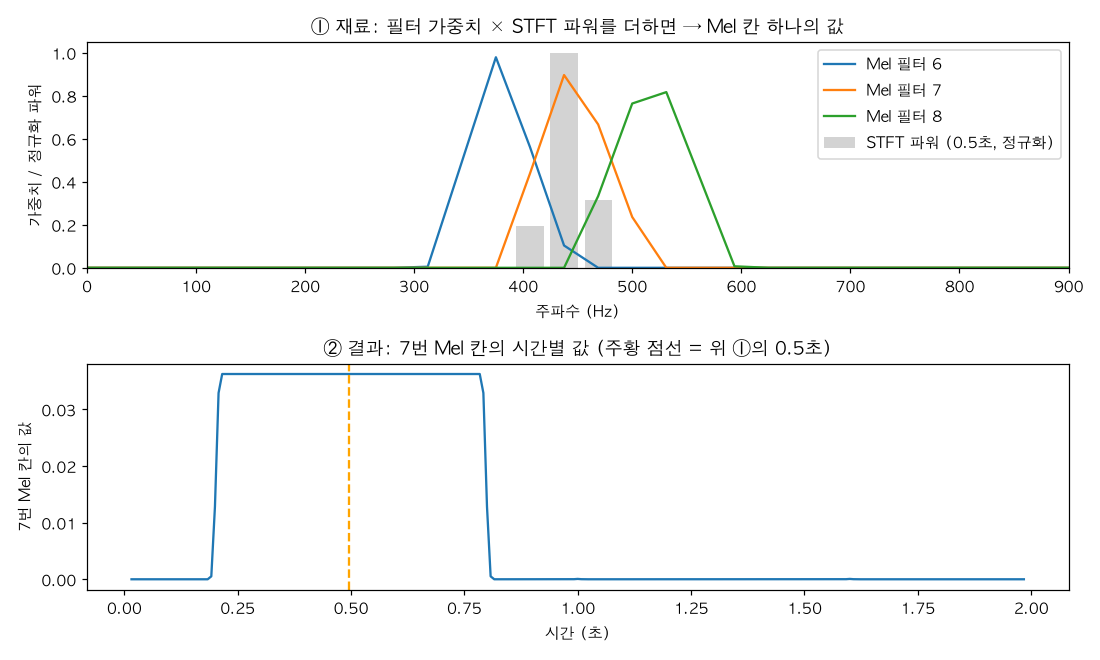

In [ ]:
# 2-G의 위 그래프(필터 가중치)와 아래 그래프(Mel 파워)가 어떻게 이어지는지 숫자로 확인
# (앞 셀의 hz, times, power, mel_filters, mel_power, sr를 그대로 사용)
# 1) 아래 그래프의 한 칸 = 위 그래프의 한 필터 × 그 시간의 STFT 파워 (가중합)
k, t = 7, int(np.argmin(np.abs(times - 0.5)))              # 7번 Mel 칸, 0.5초에 가까운 시간 칸
manual = float(np.sum(mel_filters[k] * power[:, t]))        # 필터 k의 가중치 257개 × 파워 257개를 곱해 더함
print(f'mel_power[{k}, {t}] = {mel_power[k, t]:.6f}  /  직접 계산한 가중합 = {manual:.6f}  / 같은가? {np.isclose(mel_power[k, t], manual)}')

# 2) 소리가 나는 시간에 어느 Mel 칸이 가장 강한가 (아래 그래프에서 밝은 줄이 있는 높이)
print('\n시간 | 가장 강한 Mel 칸 | 그 칸의 가운데 주파수')
edges_hz = 700.0 * (10.0 ** (np.linspace(0, 2595.0 * np.log10(1.0 + (sr / 2) / 700.0), 42) / 2595.0) - 1.0)
centers = edges_hz[1:-1]
for target in (0.5, 1.2):
    col = int(np.argmin(np.abs(times - target)))
    row = int(np.argmax(mel_power[:, col]))
    print(f'{target:3.1f}초 | {row:2d}번 | {centers[row]:7.1f} Hz')

# 3) 위 그래프에 그려진 5개 필터(0, 8, 16, 24, 32번)로 이 소리를 읽을 수 있나?
shown = list(range(0, 40, 8))
print('\n위 그래프에 그려진 필터:', shown)
for freq_bin, name in ((14, '440Hz 음(437.5Hz 칸)'), (28, '880Hz 음(875.0Hz 칸)')):
    hit = [int(i) for i in np.nonzero(mel_filters[:, freq_bin])[0]]
    print(f'{name}에 가중치가 있는 필터: {hit}  → 그려진 5개에 포함? {any(h in shown for h in hit)}')

# 4) 위 그래프의 재료가 아래 그래프의 한 줄로 이어지는 모습 (7번 Mel 칸, 0.5초)
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
spec = power[:, t] / power[:, t].max()                       # 0.5초의 STFT 파워 (최댓값을 1로 맞춤)
axes[0].bar(hz, spec, width=25, color='lightgray', label='STFT 파워 (0.5초, 정규화)')
for kk in (6, 7, 8):
    axes[0].plot(hz, mel_filters[kk], label=f'Mel 필터 {kk}')
axes[0].set(xlim=(0, 900), xlabel='주파수 (Hz)', ylabel='가중치 / 정규화 파워',
            title='① 재료: 필터 가중치 × STFT 파워를 더하면 → Mel 칸 하나의 값')
axes[0].legend()
axes[1].plot(times, mel_power[7])
axes[1].axvline(times[t], color='orange', linestyle='--')
axes[1].set(xlabel='시간 (초)', ylabel='7번 Mel 칸의 값', title='② 결과: 7번 Mel 칸의 시간별 값 (주황 점선 = 위 ①의 0.5초)')
plt.tight_layout()
plt.show()


#### 4. 결과 읽기
- **1) 같은가?** `mel_power[7, 60]`(아래 그래프의 한 칸)이 `필터 7 × 0.5초의 STFT 파워`를 직접 곱해서 더한 값과 **정확히 같습니다**(`True`). 즉 아래 그래프는 위 그래프의 가중치로 계산한 값입니다.
- **2) 어느 줄이 밝나?** 0.5초(440 Hz 음)에는 **7번 Mel 칸**(가운데 444.6 Hz)이, 1.2초(880 Hz 음)에는 **12번 Mel 칸**(가운데 856.4 Hz)이 가장 강합니다. 아래 그래프에서 **밝은 가로 띠가 나타나는 높이**가 7번 근처와 12번 근처입니다. 소리의 주파수가 올라가면 밝은 줄도 위쪽 번호로 올라갑니다.
- **3) 위 그래프로 이것을 읽을 수 있나?** **직접은 안 됩니다.** 위 그래프는 8개 간격으로 **0, 8, 16, 24, 32번**만 그리는데, 440 Hz 음은 **6, 7번** 필터에, 880 Hz 음은 **12, 13번** 필터에 걸리기 때문에 그려진 5개에는 **포함되지 않습니다**(출력의 `포함? False`). 위 그래프는 "필터가 대체로 이런 모양이고 높아질수록 넓어진다"를 보여 주는 용도이고, **실제로 어떤 필터가 반응하는지는 아래 그래프와 필터 번호로 확인**합니다.

#### 5. 그림에서 보이는 "재료 → 결과" (위 코드 셀의 그림)
- **①(위)**: 0.5초의 STFT 파워(회색 막대)는 **437.5 Hz 칸에서 가장 큽니다.** 이 칸에서 **필터 7의 가중치는 0.896, 필터 6은 0.104, 필터 8은 0**입니다. 그래서 가중합 결과는 **7번이 가장 크고(`0.0362`), 6번이 조금(`0.0065`), 8번이 더 조금(`0.0032`, 다른 칸의 기여)** 입니다.
- **②(아래)**: 7번 Mel 칸의 값을 시간에 따라 그리면 **소리가 나는 약 0.2~0.8초에만 높고** 나머지는 0입니다. 주황 점선(0.5초)의 높이가 ①에서 계산한 값입니다.
- 정리: **① 한 시각의 "주파수 방향" 계산(가중합)을 모든 시각에 반복해서 쌓은 것이 ②와 아래 그래프(2-G)입니다.**

#### 6. 헷갈리기 쉬운 점 (★)
- 위 그래프의 **가로축은 Hz, 아래 그래프의 가로축은 시간**입니다. 두 그래프의 가로축은 서로 다른 것이라 위아래로 맞춰서 읽으면 안 됩니다. **이어주는 것은 "필터 번호"** 입니다.
- 아래 그래프에서 **색이 밝다 = 그 시간에 그 필터의 주파수 대역에 소리가 있다**입니다. 위 그래프의 가중치(0~1)와는 값의 의미가 다릅니다(가중치는 비율, 아래는 가중합된 파워).
- 소리가 없는 시간(처음 약 0.15초, 약 0.8~1.0초 등)은 모든 필터가 반응하지 않아 아래 그래프도 어둡습니다(이 WAV의 첫 구간 Mel 파워는 정확히 0).
- 필터가 **서로 겹치기** 때문에(바로 아래의 pop quiz 참고) 한 주파수가 **이웃한 두 줄**(6·7번, 12·13번)에 나눠서 나타납니다.


### POP QUIZ — 삼각형 필터의 가운데 값은 무엇을 의미하나?

수치는 이 노트북의 `apply_mel_filters()`(2-E)와 같은 조건(`sr=16000`, 창 512, `n_mels=40`)으로 직접 계산해서 확인했습니다.

#### 1. 한 줄 답
**삼각형의 가운데 = 그 Mel 필터의 "중심(대표) 주파수"이고, 그 주파수에서 가중치가 가장 큰 값 `1`** 입니다. 이 Mel 칸 하나가 **"여기 주파수의 파워를 가장 많이 반영한다"** 는 뜻이고, 가운데에서 **왼쪽·오른쪽으로 멀어질수록 반영 비율이 0까지 줄어듭니다.**
- "가운데 **값**" 은 두 가지로 읽을 수 있고 둘 다 맞습니다.
  - **가중치 값 = 1** (그 필터에서 가장 크게 반영).
  - **가운데 위치 = 그 필터의 중심 주파수(Hz)** (이 Mel 칸을 대표하는 주파수).

#### 2. 수업 코드에서 찾기 (2-E `apply_mel_filters()`)
```python
mel_edges = np.linspace(hz_to_mel(0), hz_to_mel(sr / 2), n_mels + 2)   # Mel 눈금에서 기준점 42개를 같은 간격으로
edges = mel_to_hz(mel_edges)                                            # 각 기준점이 몇 Hz인지

for k in range(n_mels):
    left, center, right = edges[k:k+3]       # k번째 필터의 기준점 3개: 왼쪽 끝, 가운데, 오른쪽 끝
    filters[k] = np.maximum(
        0,
        np.minimum(
            (hz - left) / (center - left),    # 왼쪽에서 가운데로 올라가는 변
            (right - hz) / (right - center)   # 가운데에서 오른쪽으로 내려가는 변
        )
    )
```
- **`hz == center`일 때**: `(center - left) / (center - left) = 1`, `(right - center) / (right - center) = 1`이라서 `min(1, 1) = 1`입니다. 그래서 **가운데의 가중치는 정확히 1**입니다.
- **`hz == left` 또는 `hz == right`일 때** 분자가 0이라 가중치는 0입니다. `np.maximum(0, …)`은 삼각형 밖(음수)을 0으로 만듭니다.
- 2-G 그림 `axes[0].plot(hz, mel_filters[::8].T)`에서 5개 삼각형의 **꼭대기가 가운데**입니다.

#### 3. 숫자로 확인 (아래 코드 셀)


In [ ]:
# 삼각형 필터의 "가운데"가 무엇을 뜻하는지 숫자로 확인 (앞 셀의 hz, mel_filters, sr을 그대로 사용)
hz_to_mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0)
mel_to_hz = lambda mel: 700.0 * (10.0 ** (mel / 2595.0) - 1.0)
edges = mel_to_hz(np.linspace(hz_to_mel(0), hz_to_mel(sr / 2), 40 + 2))   # 기준점 42개 (필터 40개 + 2)
centers = edges[1:-1]                                                     # k번째 필터의 가운데 = edges[k+1]

# 1) 가운데 = 그 필터의 대표(중심) 주파수. 가장 큰 가중치를 가진 STFT 칸이 그 근처에 있습니다.
print('필터 | 가운데 주파수(식) | 가중치가 가장 큰 STFT 칸 | 그 칸의 가중치')
for k in [0, 8, 16, 24, 32]:
    j = int(mel_filters[k].argmax())
    print(f'{k:4d} | {centers[k]:10.1f} Hz | {hz[j]:10.1f} Hz | {mel_filters[k, j]:.3f}')

# 2) 필터 k의 왼쪽 끝·오른쪽 끝은 이웃 필터들의 가운데입니다 (edges[k], edges[k+2])
k = 8
print(f'\n필터 {k}: 왼쪽 끝 {edges[k]:.1f} Hz = 필터 {k-1}의 가운데 {centers[k-1]:.1f} Hz')
print(f'필터 {k}: 오른쪽 끝 {edges[k+2]:.1f} Hz = 필터 {k+1}의 가운데 {centers[k+1]:.1f} Hz')

# 3) 이웃한 두 필터의 가운데 사이에서는 두 삼각형의 가중치를 더하면 1입니다.
inside = (hz >= centers[0]) & (hz <= centers[-1])
total = mel_filters.sum(axis=0)
print(f'\n첫 가운데({centers[0]:.1f} Hz)~마지막 가운데({centers[-1]:.1f} Hz) 사이 칸의 가중치 합: '
      f'최소 {total[inside].min():.3f} / 최대 {total[inside].max():.3f}')


필터 | 가운데 주파수(식) | 가중치가 가장 큰 STFT 칸 | 그 칸의 가중치
   0 |       44.4 Hz |       31.2 Hz | 0.704
   8 |      517.1 Hz |      531.2 Hz | 0.817
  16 |     1290.1 Hz |     1281.2 Hz | 0.925
  24 |     2554.1 Hz |     2562.5 Hz | 0.959
  32 |     4620.8 Hz |     4625.0 Hz | 0.987

필터 8: 왼쪽 끝 444.6 Hz = 필터 7의 가운데 444.6 Hz
필터 8: 오른쪽 끝 594.3 Hz = 필터 9의 가운데 594.3 Hz

첫 가운데(44.4 Hz)~마지막 가운데(7481.4 Hz) 사이 칸의 가중치 합: 최소 1.000 / 최대 1.000


#### 4. 출력 읽기
- **가운데 주파수(식)**: 필터 0은 44.4 Hz, 8은 517.1 Hz, 16은 1290.1 Hz, 24는 2554.1 Hz, 32는 4620.8 Hz입니다. **필터 번호가 클수록 가운데 주파수가 높습니다.**
- **간격이 점점 벌어집니다.** Mel 눈금에서는 가운데들이 같은 간격(약 69 Mel)이지만 Hz로 읽으면 낮은 쪽은 촘촘하고 높은 쪽은 넓습니다(1-D의 Hz-Mel 곡선과 같은 이유).
- **이웃과 맞물립니다.** 필터 8의 왼쪽 끝(444.6 Hz)은 필터 7의 가운데이고, 오른쪽 끝(594.3 Hz)은 필터 9의 가운데입니다. **한 필터의 가운데에서는 이웃 필터의 가중치가 0**입니다.
- **가운데 사이의 가중치 합은 1입니다.** 첫 가운데부터 마지막 가운데 사이의 모든 칸에서 모든 필터의 가중치를 더하면 최소·최대가 모두 `1.000`입니다. 한 삼각형이 내려가는 만큼 이웃 삼각형이 올라가서, **어떤 주파수의 파워도 필터들에 100% 나눠서 반영**됩니다(빠지거나 중복되지 않음).

#### 5. 주의: "가운데 가중치 1"과 실제 표의 숫자가 다른 이유 (★)
- 식으로는 가운데가 정확히 1이지만, STFT 주파수 칸은 **31.25 Hz 간격으로 띄엄띄엄**이라 필터의 가운데 주파수와 칸 위치가 딱 맞는 일은 드뭅니다. 그래서 실제 `mel_filters` 표에서 **필터별 가장 큰 가중치는 `0.704 ~ 0.995`** 입니다(중앙값 약 `0.96`).
- 위 출력에서 필터 0은 가운데가 44.4 Hz인데 가장 가까운 칸이 31.2 Hz(가중치 `0.704`)입니다. **낮은 주파수 필터는 폭이 좁아서**(약 92 Hz, 칸 간격 31.25 Hz의 3배 정도) 가장 큰 값이 1에서 많이 벗어납니다. 높은 쪽 필터(필터 32: `0.987`)는 거의 1입니다.
- 틀린 것이 아니라 **칸이 이산적이라서 생기는 차이**입니다.

#### 6. 헷갈리기 쉬운 점
- **가운데 가중치 1은 "소리가 크다"는 뜻이 아닙니다.** 가중치는 **얼마나 반영할지의 비율**이고, 소리의 크기는 `power`(입력 파워)에 들어 있습니다. 같은 가중치 1이라도 그 주파수의 파워가 0이면 결과도 0입니다.
- **가운데 주파수는 "그 Mel 칸의 이름표"** 처럼 생각할 수 있습니다. 예를 들어 필터 16의 Mel 값은 "약 1290 Hz 부근(필터 15와 17의 가운데 사이)의 파워를 가운데 쪽에 무게를 실어 요약한 값"입니다.
- 2-A에서 연습한 `[1.0, 0.5, 0, 0]`(첫 칸 1.0, 옆 칸 0.5)도 같은 구조입니다. **가운데(대표) 칸에 가장 큰 가중치를 주고 옆으로 갈수록 줄이는** 것이 삼각형 필터입니다.


---
## 3교시 · Mel 파워에서 Log-Mel 특징으로

**이번 교시의 목표:** 로그 변환 후 음성 특징의 시간 변화를 읽기

**교시가 끝나면:** Log-Mel: (40, 247)


### 실습 3-A · 숫자로 로그 변환 확인

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 1 → 0dB, 0.1 → -10dB


In [24]:
# 목적: 파워 1, 0.1, 0.01 등의 값을 로그 변환하여 dB 수치 변화와 바닥값을 확인합니다.
power_examples = np.array([1.0, 0.1, 0.01, 0.001, 0.0])
# 0에 로그를 계산하지 않도록 1e-10을 최소값으로 적용합니다.
db_examples = 10 * np.log10(np.maximum(power_examples, 1e-10))
for power_value, db_value in zip(power_examples, db_examples):
    print('파워', power_value, '→', round(float(db_value), 1), 'dB')

파워 1.0 → 0.0 dB
파워 0.1 → -10.0 dB
파워 0.01 → -20.0 dB
파워 0.001 → -30.0 dB
파워 0.0 → -100.0 dB


**실습 3-A 마무리:** 1 → 0dB, 0.1 → -10dB.


### 실습 3-B · 전체 logmel() 함수 정의

**실습 유형:** 함수 정의 · 이 셀에서 함수를 정의한 뒤 이후 실습에서 사용합니다.

**확인해야 할 결과:** STFT·Mel·로그를 묶어 재사용


In [25]:
# 목적: 모노 파형을 STFT 파워 → Mel 파워 → Log-Mel 특징으로 변환합니다.
def logmel(sound, sr, n_mels=40, frame_length=512, hop_length=128):
    """모노 파형 → STFT 파워 → Mel 파워 → Log-Mel(딕셔너리 반환)."""
    # n_mels: Mel 특징 수 / frame_length: 한 창의 샘플 수 / hop_length: 이동 샘플 수
    sound = np.asarray(sound)  # 입력 파형을 NumPy 배열로 변환

    # 모노 파형과 분석할 창 길이·이동 간격이 올바른지 검사
    if sound.ndim != 1 or not (1 <= hop_length <= frame_length <= len(sound)):
        raise ValueError('모노 파형과 유효한 창·이동 간격이 필요합니다.')

    # 이번 교육용 함수에서 허용하는 Mel 필터 개수인지 검사
    # 일반적인 Mel 변환의 절대적인 제한이 아니라 이 함수에서 정한 조건입니다.
    if not (2 <= n_mels < frame_length // 2):
        raise ValueError('Mel 칸 수가 올바르지 않습니다.')

    # 1. SciPy의 STFT: 한 시간 구간에서 여러 주파수 성분을 복소수로 계산
    hz, times, spectrum = stft(
        sound,
        fs=sr,                                  # 1초당 샘플 수
        window='hann',                          # 양 끝을 부드럽게 처리하는 창
        nperseg=frame_length,                    # 한 번에 분석할 샘플 수
        noverlap=frame_length - hop_length,      # 앞뒤 구간의 겹침 길이
        nfft=frame_length,                       # FFT 길이
        boundary=None,                          # 양쪽에 0을 덧붙이지 않음
        padded=False,                           # 마지막 구간도 0으로 채우지 않음
        detrend=False,                          # 별도의 평균값 제거 없음
        scaling='spectrum'                      # 스펙트럼 크기 기준 scaling
    )

    # 2. STFT 복소수의 크기를 제곱해 주파수별 파워 계산
    power = np.abs(spectrum) ** 2

    # 3. 별도 함수에서 삼각형 Mel 필터 생성 및 STFT 파워의 가중합 계산
    mel_power, filters = apply_mel_filters(hz, power, sr, n_mels)

    # 4. 0의 로그 계산을 방지한 뒤 파워에 로그를 취해 Log-Mel 생성
    log_mel = 10 * np.log10(np.maximum(mel_power, 1e-10))

    # 5. 특징과 함께 주파수·시간 축 및 계산 설정을 반환
    return {
        'power': power,          # STFT 파워: (주파수, 시간)
        'mel_power': mel_power,  # Mel 파워: (Mel, 시간)
        'log_mel': log_mel,      # Log-Mel: (Mel, 시간)
        'filters': filters,      # Mel 필터의 주파수별 가중치
        'hz': hz,                # STFT 주파수 칸의 위치(Hz)
        'times': times,          # 분석 시간 구간의 중심 시각(초)
        'config': {
            'sr': int(sr),
            'frame_length': frame_length,
            'hop_length': hop_length,
            'n_mels': n_mels,
            'mel_scale': 'HTK',
            'filter_normalization': 'none',
            'stft_window': 'hann',
            'stft_scaling': 'spectrum',
            'power_exponent': 2,
            'log_power_floor': 1e-10
        }
    }


**실습 3-B 마무리:** STFT·Mel·로그를 묶어 재사용.


### 실습 3-C · 공통 음성 Log-Mel 생성·모양 비교

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** STFT (257,247), Mel/로그 (40,247)


In [26]:
# 목적: 2초짜리 합성음을 STFT 파워 257칸과 Mel 파워 40칸으로 분석해 배열 모양을 확인합니다.
sr, audio = load_audio(DATA / 'tone_sequence_lesson04_16k_mono.wav')
features = logmel(audio, sr, n_mels=40)   # 합성음의 Mel 특징 40개 추출
print('원본 파형:', audio.shape, '샘플 /', f'{len(audio)/sr:.2f}초')
print('STFT 파워 (주파수, 시간):', features['power'].shape)
print('Mel 파워 (Mel, 시간):', features['mel_power'].shape)
print('로그 Mel (Mel, 시간):', features['log_mel'].shape)
display(Audio(audio, rate=sr, normalize=False))  # 실제 파일의 소리 확인
# 2교시 Mel 파워 계산과 logmel() 내부의 가중합 결과가 일치하는지 확인합니다.
assert np.allclose(features['mel_power'], mel_power)
print('2교시 Mel 파워와 일치:', np.allclose(features['mel_power'], mel_power))

원본 파형: (32000,) 샘플 / 2.00초
STFT 파워 (주파수, 시간): (257, 247)
Mel 파워 (Mel, 시간): (40, 247)
로그 Mel (Mel, 시간): (40, 247)


2교시 Mel 파워와 일치: True


**실습 3-C 마무리:** STFT (257,247), Mel/로그 (40,247).


### 실습 3-D · Mel 파워와 Log-Mel 그래프 비교

**실습 유형:** 관찰 · 실행 결과의 수치와 그림을 비교하세요.

**확인해야 할 결과:** 색상 막대 수치까지 함께 확인


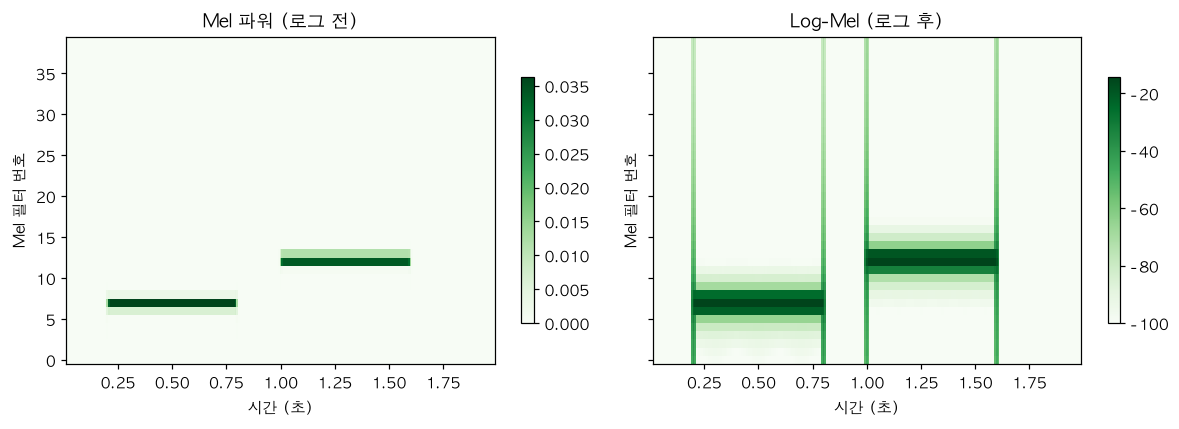

In [27]:
# 목적: 같은 음성의 Mel 파워와 Log-Mel을 나란히 비교하여 로그 변환의 효과를 관찰합니다.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
# 두 그림 모두 동일한 시간 프레임과 Mel 필터 번호(0~39)를 사용합니다.
for ax, matrix, caption in zip(
    axes,
    [features['mel_power'], features['log_mel']],
    ['Mel 파워 (로그 전)', 'Log-Mel (로그 후)']
):
    m = ax.pcolormesh(features['times'], np.arange(40), matrix,
                      shading='auto', cmap='Greens')
    ax.set(title=caption, xlabel='시간 (초)', ylabel='Mel 필터 번호')
    fig.colorbar(m, ax=ax, shrink=0.75)  # 그림별 눈금이 서로 다름에 유의
plt.tight_layout()
plt.show()
# 색의 밝기만 직접 비교하지 말고, 각 그래프의 색상 막대 숫자도 함께 읽어야 합니다.


**실습 3-D 마무리:** 색상 막대 수치까지 함께 확인.


### 실습 3-E · 시간별 강한 Mel 칸 번호

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 0.5초와 1.2초의 차이


In [28]:
# 목적: 0.5초와 1.2초에 가까운 시간 프레임에서 가장 강한 Mel 칸 번호를 관찰합니다.
for target in [0.5, 1.2]:
    column = int(np.argmin(np.abs(features['times'] - target)))  # 목표 시각에 가장 가까운 프레임
    band = features['mel_power'][:, column]                       # 해당 프레임의 Mel 40칸
    print(f'{target}초 → 가장 강한 Mel 칸: {int(np.argmax(band))}, 파워: {band.max():.6f}')

0.5초 → 가장 강한 Mel 칸: 7, 파워: 0.036236
1.2초 → 가장 강한 Mel 칸: 12, 파워: 0.033734


**실습 3-E 마무리:** 0.5초와 1.2초의 차이.


### 실습 3-F · Mel 특징 수 20개와 40개 비교

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 주파수 특징 수만 변경


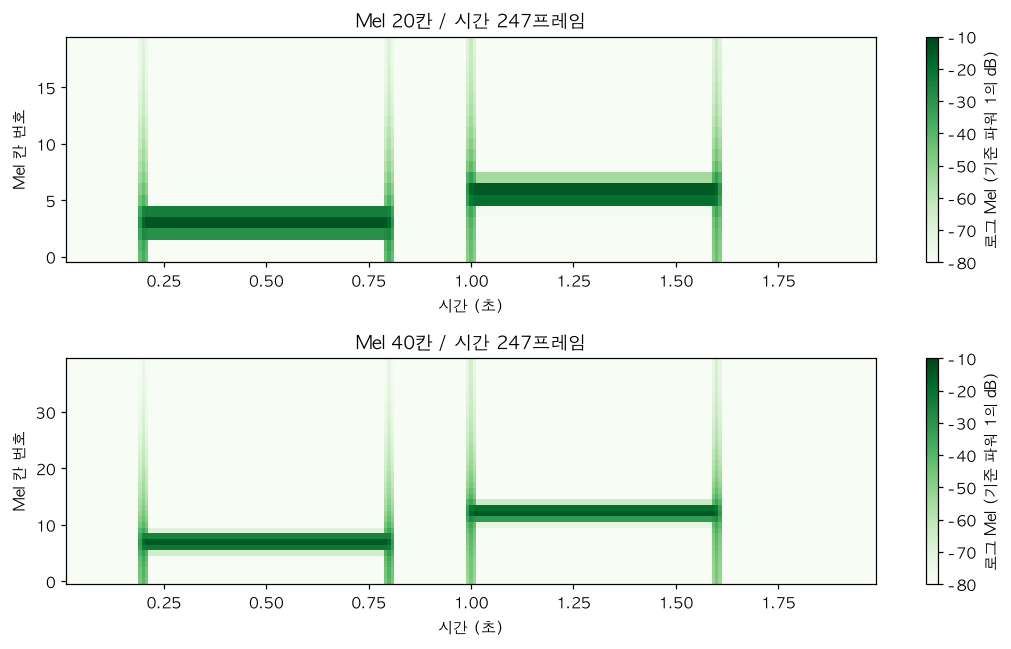

In [29]:
# 목적: 같은 소리를 Mel 20칸·40칸으로 계산해 세로축 해상도의 차이를 비교합니다.
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, count in zip(axes, [20, 40]):
    current = logmel(audio, sr, n_mels=count)  # 특징 수만 변경하여 다시 계산
    image = ax.pcolormesh(current['times'], np.arange(count), current['log_mel'],
                          shading='auto', cmap='Greens', vmin=-80, vmax=-10)
    ax.set(title=f'Mel {count}칸 / 시간 {len(current["times"])}프레임',
           xlabel='시간 (초)', ylabel='Mel 칸 번호')
    fig.colorbar(image, ax=ax, label='로그 Mel (기준 파워 1의 dB)')
plt.tight_layout()
plt.show()

**실습 3-F 마무리:** 주파수 특징 수만 변경.


### 실습 3-G · Mel 20·40 배열 크기 비교

**실습 유형:** 자율실습 · TODO를 먼저 해결한 뒤 결과를 확인하세요.

**확인해야 할 결과:** (20,247) / (40,247)


In [22]:
# 목적: 3교시 자율실습 — 특징 개수만 바꾸고 시간 프레임 수를 비교합니다.
# TODO: for 반복문과 logmel(audio, sr, n_mels=...)을 사용하세요.
# TODO: 각 결과의 log_mel.shape와 len(audio)/sr을 출력하세요.
# 이 아래에 코드를 작성하세요.

<details><summary><strong>실습 3-G · 정답 및 해설 펼치기 (먼저 스스로 작성하세요)</strong></summary>

#### 실습 3-G 정답 및 해설

**정답:** 기본 2초 합성음에서 Mel 20개는 `(20, 247)`, Mel 40개는 `(40, 247)`입니다. 주파수 정보를 묶는 출력 개수만 달라지고, 원본 길이·창·이동 간격이 같으므로 시간 프레임 수는 같습니다.

</details>


In [23]:
# 목적: 20개와 40개 Mel 특징의 배열 모양을 비교하여 Mel 축만 달라졌는지 검증합니다.
for count in [20, 40]:
    result = logmel(audio, sr, n_mels=count)  # 나머지 분석 설정은 동일
    print(f'Mel {count}개: {result["log_mel"].shape} / 음성 길이: {len(audio)/sr:.2f}초')

Mel 20개: (20, 247) / 음성 길이: 2.00초
Mel 40개: (40, 247) / 음성 길이: 2.00초


**실습 3-G 마무리:** (20,247) / (40,247).


# 현재까지 정리 퀴즈

> 1. 샘플링레이트(SR)와 재생 시간에 따라 음성 배열의 크기가 어떻게 결정되는지 설명하시오.
> 2. FFT란 무엇이며, 음성 분석에서 어떤 용도로 사용하는지 설명하시오.
> 3. STFT란 무엇이며, FFT와의 차이점 및 음성 분석에서의 용도를 설명하시오.
> 4. 음성 분석에서 Mel 필터를 사용하는 이유와 기본 원리를 설명하시오.
> 5. Log-Mel을 사용하는 이유와 로그 변환의 기본 원리를 설명하시오.

**나의 답변:**

1. 음성 배열에서 Sampling rate(SR)는 1초동안 몇 번 측정했는지를 나타내는 수치이다(단위는 Hz 사용). 재생시간(초)은 전체 샘플 수를 SR로 나눈 것이다.
2. FFT는 음성이 어떤 주파수를 가지고 있는지 확인할 수 있는 방법이다. 단, 해당 주파수가 어느 시간에 위치하는지는 알 수 없다.
3. STFT는 음성을 작은 구간(window)으로 나누어 FFT를 하는 것으로, 시간별 주파수를 알 수 있다.
4. Mel은 음성 특성을 나타내는 개수를 줄여 연산 부하를 줄이기 위해 사용한다. 원리는 (잘 모르겠다)
5. Log-Mel은 Mel이 큰 범위에서 특성 수치가 너무 작아지는 것을 방지하기 위해 사용한다. 원리는 (잘 모르겠다)

### 피드백 by claude code (강사님 제시 답변과 비교해 수정함)

> **수정 이력:** 처음에 쓴 피드백을 강사님 제시 답변(아래 "강사님 답변 예시")과 비교해서 아래를 고쳤습니다. 강사님 답변과 "나의 답변"은 그대로 두었습니다.
> 1. **5번 판정을 고쳤습니다.** 처음에는 "방향이 반대에 가깝다"고 썼는데 **부정확한 평가**였습니다. 강사님 답은 "큰 값과 작은 값의 차이가 매우 크다 → 범위를 압축해서 **상대적으로 약한 성분도** 다루기 쉽게"입니다. 사용자의 "수치가 너무 작아지는 것"은 **약한 성분이 큰 값에 묻히는 문제**를 가리킨 것으로 읽으면 방향은 일부 맞고, **표현이 부정확**한 것입니다(로그는 값을 작게 만들어서 해결하는 것이 아니라 **범위를 압축**합니다).
> 2. **1~3번의 "정확합니다"를 "핵심은 일치, 질문이 요구한 항목 보강"으로 바꿨습니다.** 질문은 1번 "배열의 **크기**", 2번 "FFT가 **무엇이며** 용도", 3번 "FFT와의 **차이점**과 용도"를 요구하는데, 답변이 일부를 직접 쓰지 않았습니다.
> 3. **2번**의 "전체 구간"을 **"분석하는 구간(전체 또는 선택한 한 구간)"** 으로 고쳤습니다. 강사님 3번 답이 "FFT는 선택한 신호 구간의 주파수 성분을 분석"이라고 쓰기 때문입니다(03 노트북 실습3이 한 구간 FFT).
> 4. **4번**의 "연산 부하" 평가를 조정했습니다. 강사님 답에는 연산 부하가 없고 **"주파수 정보를 요약"** 이라고 씁니다. 개수가 줄어드는 것은 요약의 결과입니다. "개수만 줄이는 것이 목적이면 균등하게 묶어도 된다"는 **제 추론**이라고 표시했습니다.
> 5. **5번**에 강사님 답의 세 가지를 보강했습니다: **모델이 다루기 쉽게**, **특징 개수는 바뀌지 않음**, **정규화와 비슷한 효과가 있지만 엄밀하게는 비선형 압축**.
> 6. **제출 제안**에 강사님 답의 핵심 표현을 반영했습니다.

아래 수치는 이 노트북의 4강 전용 WAV(`tone_sequence_lesson04_16k_mono.wav`)와 같은 조건(`n_mels=40`, 창 512, 이동 128)으로 직접 계산해서 확인했고, 일반 지식은 (일반 지식)으로 표시했습니다.

#### 강사님 답변과 비교 (핵심 표현 대조)
| # | 강사님 답의 핵심 | 나의 답변에 있나 | 판정 |
|---|---|---|---|
| 1 | SR = 1초에 기록하는 샘플 수, **배열 크기 = SR × 재생 시간**, 예 `(32000,)` | SR 정의 ○, 재생시간 = 샘플 수 ÷ SR ○ (**크기 = SR × 시간을 직접 쓰지 않음**) | ○ (보강) |
| 2 | **Fast Fourier Transform**, 시간 → 주파수 성분, **각 성분의 크기**, 전체에 한 번 쓰면 **시간 변화는 직접 확인 어려움** | 주파수 확인 ○, 시간 모름 ○ (**이름·크기 없음**) | ○ (보강) |
| 3 | **짧은 구간으로 나눠 각 구간에 FFT**, FFT는 선택한 구간 / STFT는 **시간에 따른 변화**, 용도: **발음·소리 변화가 언제 발생하는지** | 구간마다 FFT ○, 시간별 주파수 ○ (**FFT와의 차이·용도를 직접 쓰지 않음**) | ○ (보강) |
| 4 | **청각 특성을 참고해 주파수 정보 요약**, 낮은 쪽 촘촘·높은 쪽 넓게, **삼각형 필터 가중치 × STFT 파워 합산**, 257 → 40 | "개수를 줄여 연산 부하를 줄임" (**청각 특성·원리 없음**) | △ |
| 5 | 큰 값·작은 값 차이가 큼 → **범위 압축**, **약한 성분도 모델이 다루기 쉽게**, 개수 불변, 정규화와 비슷하지만 **비선형 압축** | "수치가 너무 작아지는 것을 방지" (**표현 부정확, 원리 없음**) | △ |

#### 1번 — SR과 재생 시간
- 핵심은 맞습니다. 질문이 **"배열의 크기가 어떻게 결정되나"** 이므로 **배열 크기(샘플 수) = SR × 재생 시간**을 직접 쓰고, 모양까지 적으면 완성입니다. 예: 16000 Hz로 2초 → 32000개, 모노 배열 모양 `(32000,)`. (재생 시간 = 샘플 수 ÷ SR은 같은 식을 거꾸로 쓴 것입니다.)
- 참고: 4강 **실습 1-A**(`샘플 개수: 32000`), 01 노트북 실습5와 나가기 문제 1.

#### 2번 — FFT
- 핵심은 맞습니다. 보강: **FFT = Fast Fourier Transform**(시간 영역 신호를 주파수 성분으로 **빠르게** 분석하는 알고리즘), 분석 결과는 주파수별 **크기**(와 위상)입니다.
- 한 가지 표현 조정: 음성 **전체에 한 번** 적용하면 시간에 따른 변화를 알기 어렵다고 쓰는 것이 강사님 표현에 가깝습니다. (FFT는 **분석하려고 고른 구간**의 주파수 성분을 봅니다. 전체를 고르면 전체, 한 구간을 고르면 그 구간입니다.)
- 참고: 4강 **실습 1-B**, 03 노트북 FFT 실습(실습2는 전체, 실습3은 한 구간).

#### 3번 — STFT
- 핵심은 맞습니다. 질문이 **"FFT와의 차이점"과 "용도"** 도 묻고 있어서 이렇게 덧붙입니다: **FFT는 선택한 구간의 주파수 성분, STFT는 구간을 옮겨 가며 반복해서 시간에 따른 변화**를 봅니다. **용도: 발음·소리의 변화가 언제 발생하는지 확인.**
- 구간을 **겹쳐 가며** 나누고 결과가 **시간 × 주파수 표**(이 노트북에서 `(257, 247)`)라는 점도 함께 쓸 수 있습니다.
- 참고: 4강 **실습 1-B**와 **3-C**(배열 모양), 03 노트북의 STFT와 pop quiz(창이 크면 주파수는 세밀하고 시간은 흐려짐).

#### 4번 — Mel (원리 쓰기)
**평가:** "개수를 줄인다"는 결과로서는 맞습니다(`(257, 247)` → `(40, 247)`). 다만 강사님 답의 이유는 **"사람의 청각적 주파수 지각 특성을 참고하여 주파수 정보를 **요약**하기 위해"** 입니다. "연산 부하" 표현은 강사님 답에 없고, 이 노트북에서 연산 시간이 얼마나 줄어드는지도 측정하지 않았습니다. 이 수업의 핵심은 **"귀 기준으로 묶는다"** 입니다(1교시 목표 "Mel이 필요한 이유"). 개수만 줄이는 것이 목적이었다면 균등하게 묶어도 되는데 굳이 낮은 쪽을 촘촘하게 묶는 이유가 귀의 특성이라는 것이 제 **추론**이고, 강사님 답도 같은 방향("낮은 주파수는 촘촘하게, 높은 주파수는 상대적으로 넓게")입니다.

**원리 한 문장:** Hz를 귀 기준 눈금인 **Mel로 바꾸고, 그 눈금에서 같은 간격으로 삼각형 필터 40개를 놓은 뒤, 각 필터의 가중치를 STFT 파워에 곱해서 더해(가중합)** 칸 하나로 요약한다(강사님 답과 같은 내용).
```text
STFT 파워 (257칸, Hz 균등)  ──삼각형 Mel 필터 40개로 가중합──▶  Mel 파워 (40칸, 낮은 쪽 촘촘·높은 쪽 넓게)
```
**어디를 보나:**
| 알고 싶은 것 | 위치 |
|---|---|
| 왜 귀 기준 눈금이 필요한가 (같은 100 Hz인데 다르게 들림) | **1-C**(듣기), **1-D**(Hz-Mel 곡선), **1-E 해설** |
| Mel이 뭔지 기초 | "Q. Mel이 뭐야?" 셀(1-C 마무리 아래) |
| 묶는 계산 (가중합) | **2-A ~ 2-C** |
| 삼각형 필터 만들기·그림 | **2-E ~ 2-G**, "두 그래프의 관계"와 pop quiz 셀 |
| 특징 개수 20 vs 40 | **3-F, 3-G** |
| 한 줄 정리 | 맨 끝 "마무리 정리": "Mel은 사람이 설계한 필터로 주파수 칸을 묶고" |

#### 5번 — Log-Mel (원리 쓰기)
**평가:** 처음 피드백의 "방향이 반대"는 고칩니다. 사용자의 의도(약한 성분이 묻히는 문제)는 강사님 답과 통하지만 **"작아지는 것을 방지"는 부정확한 표현**입니다. 로그는 값을 **작게 줄여서(압축)** 큰 값과 작은 값의 **차이가 너무 큰 문제**를 해결합니다(값 자체는 오히려 작아지거나 음수 dB가 됩니다). 이 합성음에서 Mel 파워는 **최댓값 약 0.036**인데 **0이 아닌 칸의 중앙값은 약 `4.5e-12`**(10의 -12승 수준)입니다. 선형 그림에서는 큰 값에 약한 부분이 묻혀 보이지 않습니다. 로그(dB)를 취하면 **-14 ~ -100 dB**로 압축되어 약한 부분도 구분됩니다.

**강사님 답에서 보강할 세 가지:**
1. **"모델이 다루기 쉽게"**: 강사님 답은 그림이 아니라 **모델 입력** 관점으로 씁니다(강한 성분뿐 아니라 상대적으로 약한 성분도).
2. **"특징 개수를 변경하지 않는다"**: 로그를 취해도 `(40, 247)` 그대로입니다(3-C 출력).
3. **"정규화와 유사한 효과가 있지만 엄밀하게는 비선형 압축 변환"**: 값의 범위를 줄여 다루기 쉽게 만든다는 점에서 정규화와 비슷하게 말하지만, 평균·표준편차를 맞추는 정규화가 아니라 **로그라는 비선형 함수로 범위를 압축**하는 변환입니다.

**원리 한 문장:** Mel 파워에 `10 × log10`(dB)을 취하여 **값의 범위를 압축**하고, **곱셈 차이(몇 배)를 덧셈 차이(몇 dB)로 바꿔서** 큰 값과 작은 값을 함께 다루기 쉽게 한다. **잡음을 없애는 것은 아니다.**
- 3-A: `파워 1 → 0 dB`, `0.1 → -10 dB`, `0.01 → -20 dB` (**10배마다 -10 dB**).
- **0은 -100 dB 바닥값**으로 처리합니다(`np.maximum(mel_power, 1e-10)`). 이 WAV의 Mel 파워 칸 중 **36.8%가 정확히 0**이어서 -100 dB가 됩니다.
- (일반 지식) 사람 귀가 소리 세기를 로그에 가깝게 느낀다는 점도 로그를 쓰는 이유로 흔히 설명됩니다. 이 노트북과 강사님 답에서 확인한 내용은 아닙니다.

**어디를 보나:**
| 알고 싶은 것 | 위치 |
|---|---|
| 로그 변환이 숫자를 어떻게 바꾸나 | **3-A** |
| 코드 어디에서 로그를 취하나 | **3-B** `logmel()`의 4번 줄 (`10 * np.log10(np.maximum(mel_power, 1e-10))`) |
| 로그 전후 그림 비교 | **3-D** (그림별 색 막대 눈금이 다름에 주의) |
| 파워와 dB의 관계 | "'파워(power)'가 뭐야?" 셀 (3~4절) |
| 강사님 한 줄 정의 | 맨 끝 자기평가표: "로그 변환 의미 설명 = 큰 값 차이의 로그 표현, **잡음 제거 아님**" |

### 최종 제출 제안 (강사님 답의 핵심 표현 반영)

아래는 사용자가 쓴 문장을 살리면서, **질문이 요구한 항목**과 **강사님 답의 핵심 표현**을 넣은 제출용 예시입니다.

> **정리 퀴즈**
> 1. 음성 배열에서 Sampling rate(SR)는 1초 동안 몇 번 측정(기록)했는지를 나타내는 수치이다(단위는 Hz). 모노 음성 배열의 크기(샘플 수)는 SR × 재생 시간(초)으로 결정된다. 예를 들어 16000 Hz로 2초면 32000개이고 배열 모양은 (32000,)이다. 거꾸로 재생시간(초)은 전체 샘플 수를 SR로 나눈 것이다.
> 2. FFT(Fast Fourier Transform)는 시간 영역의 음성 신호를 주파수 성분으로 빠르게 분석하는 방법으로, 음성에 어떤 주파수가 얼마나(크기) 들어 있는지 확인하는 데 쓴다. 단, 음성 전체에 한 번 적용하면 그 주파수가 어느 시간에 나타나는지(시간에 따른 변화)는 직접 알기 어렵다.
> 3. STFT(Short-Time Fourier Transform)는 음성을 작은 구간(window)으로 나누어 각 구간에 FFT를 하는 것이다. FFT가 선택한 구간의 주파수 성분을 본다면, STFT는 시간별 주파수 변화를 볼 수 있어서 발음이나 소리의 변화가 언제 발생하는지 확인하는 데 쓴다.
> 4. Mel 필터는 사람이 주파수를 듣는 특성(청각 특성)을 참고하여 주파수 정보를 요약하기 위해 사용한다. 원리는 낮은 주파수에는 필터를 촘촘하게, 높은 주파수에는 넓게 배치하고, 삼각형 필터의 가중치를 STFT 파워에 곱해서 더하는 것이다. 예를 들어 257개 주파수 파워를 40개 Mel 특징으로 요약한다(그 결과 특징 수가 줄어든다).
> 5. Log-Mel은 Mel 파워에 로그(dB)를 적용한 특징이다. Mel 파워는 큰 값과 작은 값의 차이가 매우 커서, 로그로 값의 범위를 압축하면 강한 성분뿐 아니라 약한 성분도 모델이 다루기 쉬워진다. 원리는 10×log10으로 몇 배 차이를 몇 dB의 덧셈 차이로 바꾸는 것이다. 특징 개수(40)는 바뀌지 않고, 정규화와 비슷한 효과가 있지만 엄밀하게는 비선형 압축이며 잡음 제거가 아니다.

**제출 전 점검:**
- **내 말투로 줄여도 됩니다.** 위 문장은 강사님 답과 가깝게 맞춘 것이라, 시간이 부족하면 1~3번은 **원래 쓴 문장 + 질문이 요구한 한 가지**(1번 `배열 크기 = SR × 초`, 2번 `Fast Fourier Transform`, 3번 `FFT와의 차이`)만 덧붙여도 충분합니다.
- 4번 "연산 부하"를 남기고 싶으면 "특징 수가 줄어 모델 입력이 작아진다" 정도로 쓰고, **"사람의 청각 특성을 참고한 요약"** 이라는 핵심은 꼭 넣으세요.
- 5번의 원리가 어려우면 **3-A 숫자(1 → 0, 0.1 → -10, 0.01 → -20)** 를 예로 적는 것이 가장 쉽고 정확합니다.

**강사님 답변 예시:**

**1번. 음성 배열과 샘플링레이트**

샘플링레이트(SR)는 1초 동안 음성을 몇 개의 샘플로 기록하는지를 나타낸다. 모노 음성의 배열 크기는 샘플링레이트와 재생 시간을 곱하여 계산한다.
예를 들어 16,000Hz로 2초 동안 녹음하면 32,000개의 샘플이 생성되며, 배열의 크기는 (32000,)이 된다.

**2번. FFT의 개념과 용도**

FFT(Fast Fourier Transform)는 시간 영역의 신호를 주파수 성분으로 빠르게 분석하는 알고리즘이다.
음성에 포함된 주파수 성분과 각 성분의 크기를 분석하는 데 사용한다. 다만 음성 전체에 FFT를 한 번 적용하면 주파수 성분이 시간에 따라 어떻게 변하는지는 직접 확인하기 어렵다.

**3번. STFT의 개념과 용도**

STFT(Short-Time Fourier Transform)는 음성을 짧은 시간 구간으로 나누고, 각 구간에 FFT를 적용하는 분석 방법이다.
FFT가 선택한 신호 구간의 주파수 성분을 분석한다면, STFT는 시간에 따른 주파수 성분의 변화를 분석한다.
음성의 발음이나 소리의 변화가 언제 발생하는지 확인하는 데 사용한다.

**4번. Mel 필터의 사용 이유와 원리**

Mel 필터는 사람의 청각적 주파수 지각 특성을 참고하여 주파수 정보를 요약하기 위해 사용한다.
낮은 주파수에서는 필터를 촘촘하게 배치하고, 높은 주파수에서는 상대적으로 넓게 배치한다. 각 삼각형 필터의 가중치를 STFT 파워에 곱하고 합산하여 Mel 특징을 생성한다.
예를 들어 257개의 STFT 주파수 파워를 40개의 Mel 특징으로 요약할 수 있다.

**5번. Log-Mel의 사용 이유와 원리**

Log-Mel은 Mel 필터로 계산한 파워 값에 로그를 적용한 음성 특징이다.
Mel 파워는 큰 값과 작은 값의 차이가 매우 클 수 있다. 로그 변환은 이러한 값의 범위를 압축하여 강한 성분뿐 아니라 상대적으로 약한 성분도 모델이 다루기 쉽게 만든다.
로그 변환은 특징 개수를 변경하지 않으며, 정규화와 유사한 효과가 있지만 엄밀하게는 비선형 압축 변환이다.


---
# 2026.10.26(월) 22h30~

## 4교시 · Log-Mel을 모델 입력으로 준비

**이번 교시의 목표:** 축 변경·배치·저장·선택 실음성 실습

**교시가 끝나면:** 모델 입력: (1, 247, 40)


### 실습 4-A · 특징·시간 배열의 축 바꾸기

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** (40,247) → (247,40)


In [30]:
# 목적: 로그 Mel 배열의 (특징, 시간)을 (시간, 특징)으로 전치합니다.
mel = features['log_mel'].astype(np.float32)  # 신경망 입력에 흔한 float32 형태
sequence = mel.T                             # (Mel, 시간) → (시간, Mel)
print('분석용:', mel.shape, '/ 시간 순서:', sequence.shape)
print('첫 시간 프레임의 특징 모양:', sequence[0].shape)

분석용: (40, 247) / 시간 순서: (247, 40)
첫 시간 프레임의 특징 모양: (40,)


**실습 4-A 마무리:** (40,247) → (247,40).


### 실습 4-B · 배치 축 직접 추가하기

**실습 유형:** 자율실습 · TODO를 먼저 해결한 뒤 결과를 확인하세요.

**확인해야 할 결과:** (247,40) → (1,247,40)


In [25]:
# 목적: 4교시 자율실습 — (Mel,시간)→(시간,Mel)→(배치,시간,Mel)로 변환합니다.
# TODO: features['log_mel']에서 시작하세요.
# TODO: .T, .astype(np.float32), [None, :, :]를 적용하고 각 shape를 출력하세요.
# 이 아래에 코드를 작성하세요.

<details><summary><strong>실습 4-B · 정답 및 해설 펼치기 (먼저 스스로 작성하세요)</strong></summary>

#### 실습 4-B 정답 및 해설

배치의 의미는 *현재 음성 파일 1개를 하나의 입력 묶음으로 만든 것*입니다. 실제 모델의 요구 축 순서가 다르면 모델 문서에 맞게 바꿔야 합니다.

**추가 확인 조건 예시:** SR, Mel 필터 수와 척도, 로그 및 정규화, 창/홉, 패딩 길이, 축 순서.

</details>


In [31]:
# 목적: 하나의 합성음을 (배치 1개, 시간 프레임, Mel 40개) 배열로 만들어 확인합니다.
sample = features['log_mel'].T.astype(np.float32)  # (시간, Mel)
batch = sample[None, :, :]                        # 맨 앞에 배치 축 추가
print('Mel·시간:', features['log_mel'].shape)
print('시간·Mel:', sample.shape)
print('배치·시간·Mel:', batch.shape)
assert batch.ndim == 3 and batch.shape[0] == 1 and batch.shape[2] == 40

Mel·시간: (40, 247)
시간·Mel: (247, 40)
배치·시간·Mel: (1, 247, 40)


**실습 4-B 마무리:** (247,40) → (1,247,40).


### 실습 4-C · 숫자 특징과 설정 저장·검증

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** NPY + UTF-8 JSON


In [32]:
# 목적: 로그 Mel 숫자와 처리 조건을 별도 파일로 저장하고, 다시 읽어 값이 같은지 확인합니다.
np.save(RESULTS / 'lesson04_logmel.npy', mel)  # 특징 배열 저장
my_mel_explanation = '미작성: Mel 칸 번호와 Hz가 왜 다른지 적으세요.'
my_model_conditions = '미작성: 모델 입력 전 확인할 조건 두 가지를 적으세요.'
record = {
    'lesson': 4, 'example_id': 'tone_sequence', 'config': features['config'],
    'shape_mel_time': list(mel.shape),
    'Mel과_주파수축의_차이': my_mel_explanation,
    '모델에_넣기_전_확인할_조건': my_model_conditions
}
save_json(RESULTS / 'lesson04_record.json', record)  # 한글 포함 설정 저장
loaded = np.load(RESULTS / 'lesson04_logmel.npy')  # 저장된 숫자 파일 확인
print('저장 전후 값 동일:', np.array_equal(loaded, mel))

저장 전후 값 동일: True


**실습 4-C 마무리:** NPY + UTF-8 JSON.


### 실습 4-D · 실제 목소리 비교 (선택)

**실습 유형:** 선택 실습 · 파일이 있는 경우에만 실행합니다.

**확인해야 할 결과:** my_voice.wav가 있을 때만


원본: 44100Hz / 2채널 / 7.960초
변환: 16000Hz / 127360샘플 / 7.960초
로그 Mel (Mel, 시간): (40, 992)


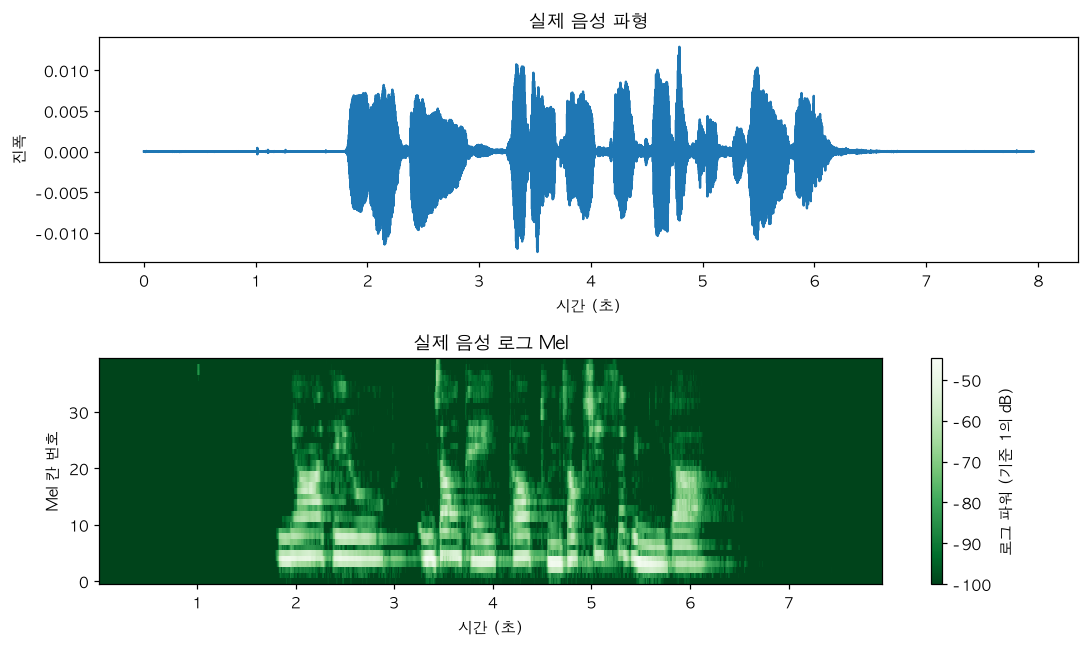

In [38]:
# 목적: 개인 녹음 파일이 있으면 모노·16kHz로 변환하고 로그 Mel 특징/그래프를 생성합니다.
voice_path = next((p for p in [DATA / 'my_voice.wav', Path('my_voice.wav')] if p.is_file()), None)
if voice_path is None:
    print('확장 실습 안내: my_voice.wav가 없으므로 실제 음성 실습만 건너뜁니다.')
    voice_features = None
else:
    voice_sr, voice_raw = load_audio(voice_path)  # PCM16 파일 읽기
    voice_channels = 1 if voice_raw.ndim == 1 else voice_raw.shape[1]  # 채널 확인
    voice_mono = voice_raw if voice_channels == 1 else voice_raw.mean(axis=1)  # 스테레오→모노
    common = gcd(voice_sr, 16000)  # 리샘플링 비율 간단히 만들기
    voice_16k = resample_poly(voice_mono, 16000 // common, voice_sr // common)
    if len(voice_16k) < 512:
        raise ValueError('0.032초 미만의 파일은 창 512샘플을 확보할 수 없습니다.')
    voice_features = logmel(voice_16k, 16000, n_mels=40)  # 실제 음성 Mel 계산
    voice_mel = voice_features['log_mel'].astype(np.float32)
    print(f'원본: {voice_sr}Hz / {voice_channels}채널 / {len(voice_mono)/voice_sr:.3f}초')
    print(f'변환: 16000Hz / {len(voice_16k)}샘플 / {len(voice_16k)/16000:.3f}초')
    print('로그 Mel (Mel, 시간):', voice_mel.shape)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6))
    axes[0].plot(np.arange(len(voice_16k)) / 16000, voice_16k)  # 모노 파형
    axes[0].set(xlabel='시간 (초)', ylabel='진폭', title='실제 음성 파형')
    im = axes[1].pcolormesh(voice_features['times'], np.arange(40), voice_mel,
                            shading='auto', cmap='Greens_r')  # 시간별 로그 Mel
    axes[1].set(xlabel='시간 (초)', ylabel='Mel 칸 번호', title='실제 음성 로그 Mel')
    fig.colorbar(im, ax=axes[1], label='로그 파워 (기준 1의 dB)')
    plt.tight_layout()
    voice_fig = RESULTS / 'lesson04_my_voice_mel.png'
    fig.savefig(voice_fig, dpi=140, bbox_inches='tight')  # 그래프 저장
    plt.show()
    # display(Audio(voice_16k, rate=16000, normalize=False))  # 변환 음성 재생

### Q. "0.032초 미만의 파일은 창 512샘플을 확보할 수 없습니다"의 원리 (4-D 검사 줄)

수치와 scipy의 동작은 이 노트북의 STFT 조건(창 512, 이동 128, `boundary=None`, `padded=False`)으로 직접 실행해서 확인했습니다.

#### 1. 한 줄 원리
STFT는 소리에서 **한 번에 창(window) 512개 샘플을 꺼내서 FFT**합니다. 소리가 **512개보다 짧으면 창 하나도 채울 수 없으니** 분석이 시작될 수 없습니다. 512개가 몇 초인지는 `샘플 수 ÷ SR`이라서 **`512 ÷ 16000 = 0.032초`** 입니다(32 ms). 그래서 "0.032초 미만 = 16 kHz에서 512샘플 미만 = 창을 못 채움"입니다.
```python
if len(voice_16k) < 512:                         # 16 kHz로 바꾼 뒤의 샘플 수가 512개보다 적으면
    raise ValueError('0.032초 미만의 파일은 창 512샘플을 확보할 수 없습니다.')
```

#### 2. 왜 "리샘플링 후"의 길이를 검사하나
- 창 512개는 **16 kHz로 바꾼 배열 기준**입니다(`logmel(voice_16k, 16000, ...)`). 그래서 검사도 `voice_16k`(리샘플링 결과)의 길이로 합니다.
- 원본 SR이 다르면 원본 샘플 수는 달라지지만 **시간은 같습니다.** 예를 들어 원본이 44100 Hz라면 0.032초는 약 `1411.2`개 샘플이고, 16 kHz로 바꾸면 `512`개가 됩니다(`1411.2 × 16000 ÷ 44100 = 512`).

#### 3. 프레임 수 공식으로 보기
`프레임 수 = (샘플 수 - 창 길이) ÷ 이동 간격` 의 몫 `+ 1` (이동 128, 앞에서 본 조각 개수 공식과 같음). 샘플이 창보다 적으면 **프레임이 0개**입니다.

| 샘플 수 (16 kHz) | 길이 | 프레임 수 | 비고 |
|---|---|---|---|
| 511 | 0.03194초 | **0** | 창을 못 채움 → 이 셀의 검사에서 막힘 |
| **512** | **0.032초** | **1** | 딱 한 번 분석 가능 (최소 길이) |
| 513 ~ 639 | 0.03206 ~ 0.03994초 | 1 | 이동 128을 못 채워서 프레임은 아직 1개 |
| 640 | 0.040초 | 2 | 이동 128만큼 더 있어야 프레임이 하나 늘어남 |
| 1000 | 0.0625초 | 4 | `(1000-512)//128 + 1 = 4` |
| 127360 (내 녹음 7.96초) | 7.96초 | **992** | 출력 `(40, 992)`와 일치: `(127360-512)//128 + 1 = 992` |

#### 4. 왜 scipy에 맡기지 않고 직접 검사하나 (직접 확인)
짧은 소리를 그냥 `stft(...)`에 넣으면 이렇게 됩니다.
- **511개**: 오류 없이 **"nperseg = 512 is greater than input length = 511, using nperseg = 511"** 경고만 내고 **창을 511로 몰래 줄여서** 계산합니다(결과 모양 `(257, 1)`). 창 길이가 달라져서 **다른 조건의 특징이 조용히 만들어집니다.**
- **100개**: `ValueError: noverlap must be less than nperseg.`로 멈춥니다. **원인(소리가 너무 짧음)과 거리가 먼 메시지**입니다.
- 그래서 4-D 셀은 **먼저 직접 검사해서 이해하기 쉬운 문장으로 멈춥니다.** (`logmel()`에도 `1 ≤ 이동 ≤ 창 ≤ 샘플 수` 검사가 있어서(3-B) 소리가 창보다 짧으면 `ValueError`가 나지만, 여기서는 이유를 더 친절하게 알려 줍니다.)

#### 5. 이 노트북에서 "짧아도 계산"되지 않는 이유
- 3-B의 STFT는 `boundary=None`(양쪽에 0을 덧붙이지 않음), `padded=False`(마지막 구간을 0으로 채우지 않음)입니다. **0으로 채워서 억지로 창을 만들지 않는 설정**이라서 소리가 창보다 짧으면 방법이 없습니다. (0을 덧붙이는 설정을 쓰면 짧은 소리도 계산은 가능하지만, 이 노트북은 쓰지 않습니다. 일반 지식)

#### 6. 알아 둘 점 (★)
- **0.032초는 "계산이 가능한 최소 길이"이지 "의미 있는 분석의 최소 길이"가 아닙니다.** 이 길이에서는 프레임이 1개라 **시간에 따른 변화를 볼 수 없습니다.** 말소리는 보통 몇 초 단위이고(내 녹음 7.96초 → 프레임 992개), 실습 파일은 이보다 훨씬 깁니다.
- 이 검사가 없어도 평소 녹음에서는 오류가 나지 않습니다. **빈 파일이거나 아주 짧게 잘린 파일**을 넣었을 때를 대비한 안전장치입니다.


#### 선택 실습 4-D · 실제 음성 관찰 기록

아래 셀은 `my_voice.wav`를 준비한 학생만 실행합니다. 파일이 없으면 자동으로 건너뜁니다.


In [29]:
# 목적: 실제 목소리 분석 결과가 있을 때만 숫자 특징과 설정·관찰 기록을 저장합니다.
if voice_path is not None and voice_features is not None:
    voice_observation = '미작성: 발화 시각과 밝은 Mel 칸 범위를 적으세요.'
    voice_comparison = '미작성: 합성음과 실제 음성의 차이를 적으세요.'
    np.save(RESULTS / 'lesson04_my_voice_logmel.npy', voice_mel)  # 숫자 배열 저장
    voice_record = {
        'source_file': voice_path.name,
        'source_sr': voice_sr, 'source_channels': voice_channels,
        'processed_sr': 16000,
        'duration_seconds': round(len(voice_16k) / 16000, 4),
        'shape_mel_time': list(voice_mel.shape),
        'config': voice_features['config'],
        'figure': voice_fig.name,
        '관찰': voice_observation, '합성음과_비교': voice_comparison
    }
    save_json(RESULTS / 'lesson04_my_voice_record.json', voice_record)
    print('개인 음성 특징 및 관찰 기록 저장 완료')
else:
    print('개인 음성 파일 없음: 실제 음성 결과 저장은 건너뛰었습니다.')

개인 음성 특징 및 관찰 기록 저장 완료


**실습 4-D 마무리:** my_voice.wav가 있을 때만.


---
## 종합 P-1 · 하나의 WAV를 모델 입력 파일까지 완성

**문제 상황:** 다른 수강생이 여러분이 만든 Log-Mel 특징을 그대로 재현할 수 있어야 합니다.

**해야 할 일:** 입력 WAV 확인 → 필요시 전처리 → STFT·Mel·로그 특징 → 축 변경·배치 → 그림·배열·설정 저장 → 재읽기 검증.


In [30]:
# 목적: 종합 프로젝트 — WAV 읽기부터 입력 배열/그래프/결과 저장까지 직접 구현합니다.
# Step 1. PCM16 파일을 읽고 SR·채널 수·길이를 출력하세요.
# Step 2. 필요한 경우 모노와 16kHz로 변환하세요.
# Step 3. logmel()로 STFT 파워, 로그 Mel, 시간 값을 얻으세요.
# Step 4. 25%, 60% 시각에서 가장 큰 Mel 칸을 계산하세요.
# Step 5. (시간,Mel)→(1,시간,Mel) 배치를 만드세요.
# Step 6. np.save / save_json / plt.savefig로 3개 결과물을 저장하세요.
# Step 7. np.load와 np.array_equal로 저장값이 같은지 확인하세요.
# 이 아래에 코드를 작성하세요.

<details><summary><strong>종합 P-1 정답과 검증 체크 포인트 (직접 구현한 뒤 보세요)</strong></summary>

### Small Project 정답 코드와 검증 방법

아래는 **위쪽 실습에서 만든 `load_audio()`, `logmel()`, `save_json()`을 재사용** 하는 하나의 완성 예시입니다. 기본 입력은 합성음이므로 별도의 녹음 없이 실행됩니다.

- 기본 합성음 2초의 예상 출력: STFT `(257,247)`, 로그 Mel `(40,247)`, 배치 `(1,247,40)`.
- 본인 목소리로 바꾸면 시간 프레임 수는 음성 길이에 따라 달라질 수 있습니다.
- 이 코드의 Mel 입력은 **교육용 특징** 이며 Whisper 등 특정 음성 인식 모델의 공식 입력과 동일하다고 가정하면 안 됩니다.

</details>


입력: my_voice.wav / 44100Hz / 2채널 / 7.960초
전처리: 16000Hz / 7.960초
STFT 파워: (257, 992) 로그 Mel: (40, 992)
모델 입력 배치: (1, 992, 40)
시각별 강한 Mel 칸: [{'requested_time_s': 1.99, 'actual_time_s': 1.992, 'peak_mel_index': 4}, {'requested_time_s': 4.776, 'actual_time_s': 4.776, 'peak_mel_index': 4}]


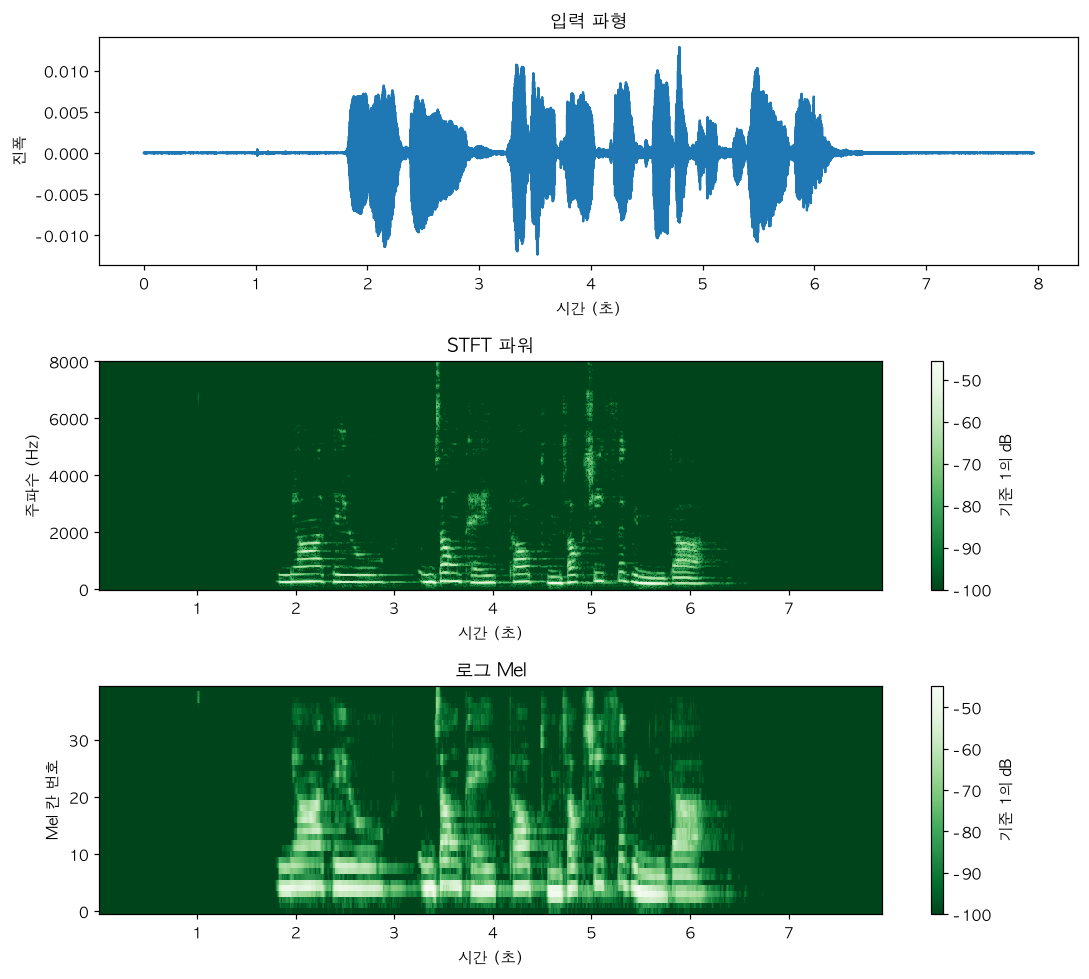

검증 성공: 저장 전후 특징 배열이 일치하며 결과물 3개가 생성되었습니다.


In [41]:
# 목적: Small Project 정답 — 음성을 전처리하고 STFT·로그 Mel·모델 입력 배열을 저장·검증합니다.
project_path = DATA / 'my_voice.wav'  # 기본 입력. 준비했다면 DATA/'my_voice.wav'로 변경 가능 / tone_sequence_lesson04_16k_mono.wav
project_sr, project_raw = load_audio(project_path)
project_channels = 1 if project_raw.ndim == 1 else project_raw.shape[1]  # 채널 수 확인
project_mono = project_raw if project_channels == 1 else project_raw.mean(axis=1)  # 모노 변환

# 샘플링레이트가 다른 경우만 폴리페이즈 리샘플링을 수행합니다.
if project_sr == 16000:
    project_16k = project_mono
else:
    factor = gcd(project_sr, 16000)
    project_16k = resample_poly(project_mono, 16000 // factor, project_sr // factor)

if len(project_16k) < 512:
    raise ValueError('음성 길이가 너무 짧습니다: 512샘플 이상이 필요합니다.')

# 같은 시간 프레임에 대해 STFT 파워→Mel 파워→로그 Mel을 계산합니다.
project_features = logmel(project_16k, 16000, n_mels=40,
                          frame_length=512, hop_length=128)
project_power = project_features['power']
project_logmel = project_features['log_mel'].astype(np.float32)
project_sample = project_logmel.T                       # (시간, Mel)
project_batch = project_sample[None, :, :]             # (배치, 시간, Mel)

# 25%, 60% 지점의 실제 시간 프레임에서 최대 Mel 칸 번호를 관찰합니다.
project_duration = len(project_16k) / 16000
project_peaks = []
for portion in [0.25, 0.60]:
    target_time = project_duration * portion
    column = int(np.argmin(np.abs(project_features['times'] - target_time)))
    mel_index = int(np.argmax(project_features['mel_power'][:, column]))
    project_peaks.append({'requested_time_s': round(target_time, 3),
                          'actual_time_s': round(float(project_features['times'][column]), 3),
                          'peak_mel_index': mel_index})

print(f'입력: {project_path.name} / {project_sr}Hz / {project_channels}채널 / {len(project_mono)/project_sr:.3f}초')
print(f'전처리: 16000Hz / {project_duration:.3f}초')
print('STFT 파워:', project_power.shape, '로그 Mel:', project_logmel.shape)
print('모델 입력 배치:', project_batch.shape)
print('시각별 강한 Mel 칸:', project_peaks)

# 분석 그림: 파형 / STFT 파워(dB) / 로그 Mel(dB)을 같은 시간 축으로 살펴봅니다.
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
axes[0].plot(np.arange(len(project_16k)) / 16000, project_16k)
axes[0].set(title='입력 파형', xlabel='시간 (초)', ylabel='진폭')
stft_db = 10 * np.log10(np.maximum(project_power, 1e-10))  # STFT 파워를 로그 눈금으로 변환
im1 = axes[1].pcolormesh(project_features['times'], project_features['hz'],
                          stft_db, shading='auto', cmap='Greens_r')
axes[1].set(title='STFT 파워', xlabel='시간 (초)', ylabel='주파수 (Hz)')
fig.colorbar(im1, ax=axes[1], label='기준 1의 dB')
im2 = axes[2].pcolormesh(project_features['times'], np.arange(40),
                          project_logmel, shading='auto', cmap='Greens_r')
axes[2].set(title='로그 Mel', xlabel='시간 (초)', ylabel='Mel 칸 번호')
fig.colorbar(im2, ax=axes[2], label='기준 1의 dB')
plt.tight_layout()
fig.savefig(RESULTS / 'project04_plot.png', dpi=130, bbox_inches='tight')
plt.show()

# 숫자 배열과 계산 방법을 함께 저장하여 재현 가능하게 합니다.
np.save(RESULTS / 'project04_features.npy', project_batch)
project_report = {
    'input_file': project_path.name, 'input_sr': project_sr,
    'input_channels': project_channels, 'processed_sr': 16000,
    'duration_s': round(project_duration, 3),
    'stft_power_shape': list(project_power.shape),
    'log_mel_shape': list(project_logmel.shape),
    'batch_shape': list(project_batch.shape),
    'peak_mel_examples': project_peaks,
    'config': project_features['config'],
    'interpretation': 'Mel 칸은 주파수 대역의 가중합이며 Hz 값 자체가 아닙니다.'
}
save_json(RESULTS / 'project04_report.json', project_report)
reloaded = np.load(RESULTS / 'project04_features.npy')
assert project_batch.shape[0] == 1 and project_batch.shape[-1] == 40
assert np.array_equal(reloaded, project_batch), '저장한 특징 배열이 다릅니다.'
print('검증 성공: 저장 전후 특징 배열이 일치하며 결과물 3개가 생성되었습니다.')

### 프로젝트 결과 확인 및 자기 평가

| 확인 항목 | 확인 방법 | 완료 |
|---|---|---|
| 입력 음성 정보 확인 | 채널·SR·길이가 출력됨 | □ |
| 전처리 수행 | 필요할 때 모노 변환·실제 리샘플링 | □ |
| STFT·Mel 차이 설명 | 주파수 257칸이 Mel 40칸으로 바뀜 | □ |
| 로그 변환 의미 설명 | 큰 값 차이의 로그 표현, 잡음 제거 아님 | □ |
| 모델 입력 배열 완성 | `(1, 시간, 40)` 모양 | □ |
| 결과물 검증 | `project04_features.npy`, `project04_report.json`, `project04_plot.png` 존재 | □ |

**마무리 정리:** STFT는 시간별 주파수를 자세히 분석하고, Mel은 사람이 설계한 필터로 주파수 칸을 묶고, 로그는 값의 범위를 변환합니다. 이후 신경망은 이 특징을 입력받아 *학습 목적에 필요한 표현*을 학습할 수 있습니다.

**다음 5강 연결:** 지금 만든 음성 특징을 **음성 파일·정답·데이터 분할·길이 맞추기**와 연결합니다.
